# Nested Clustered Optimization under Estimation Error

Public observations cannot reveal their exact population covariance or provide independent repeated histories. This notebook therefore shows every step used to generate controlled data for questions that require known truth, and it later uses the fixed public archive for the chronological comparison. Repeated generated samples measure how far estimated weights move from the weights obtained from the known population inputs:

$$
E_m^{(b)}=\left[\frac{1}{N}\sum_{i=1}^{N}\left(\widehat w_{m,i}^{(b)}-w_{m,i}^{0}\right)^2\right]^{1/2}.
$$

Here, $m$ labels an allocation method, $b$ labels an independent repetition, $N$ is the number of assets, $\widehat w_{m,i}^{(b)}$ is the estimated weight of asset $i$, $w_{m,i}^{0}$ is the weight from the known population inputs, and $E_m^{(b)}$ is the allocation root mean squared error.

,Quantity,Value
0,Assets,24
1,Blocks,4
2,Assets per block,6
3,Within-block correlation,0.55
4,Between-block correlation,0.04
5,Training observations,180
6,Repeated samples per objective,40
7,Random-state base,2202


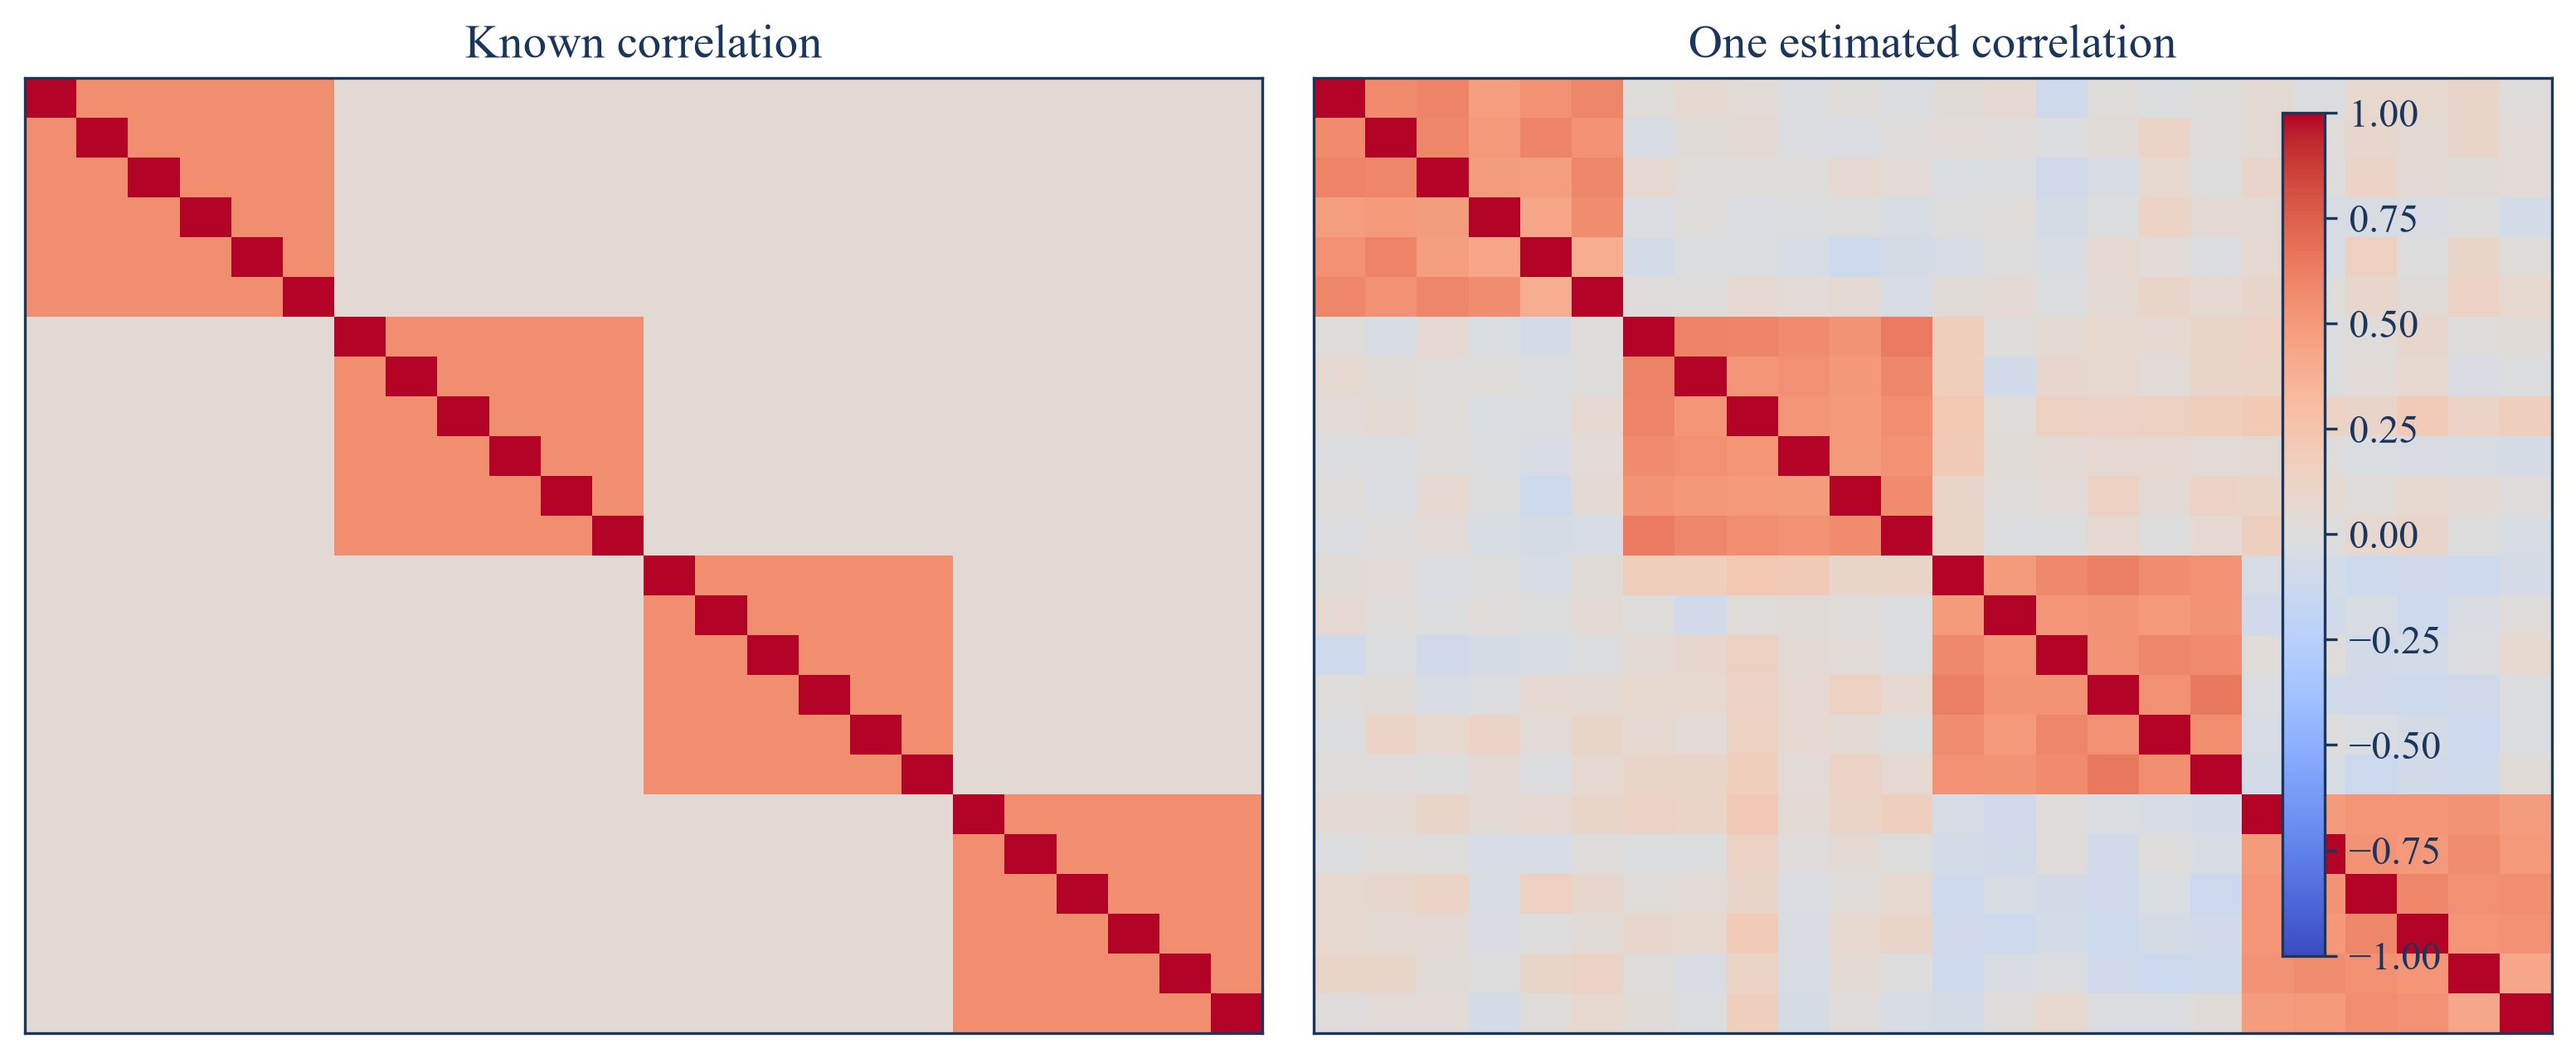

In [1]:
import re as _table_number_re
from IPython.display import HTML as _TableHTML, display as _raw_display


def compact_float_format(number_format=None):
    def format_value(value):
        if number_format is None:
            rendered = str(value)
        elif callable(number_format):
            rendered = str(number_format(value))
        else:
            rendered = number_format % value
        return compact_numeric_token(rendered)
    return format_value


def compact_numeric_token(rendered):
    if not _table_number_re.fullmatch(r"[+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?", rendered):
        return rendered
    value = float(rendered)
    if value != 0.0 and abs(value) < 5e-13:
        return "0"
    if ("." in rendered or "e" in rendered.lower()) and value.is_integer():
        return str(int(value))
    return rendered


def compact_numeric_text(text):
    pattern = r"(?<![0-9.eE])([+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?)(?![0-9.eE])"
    return _table_number_re.sub(pattern, lambda match: compact_numeric_token(match.group(0)), text)


def compact_table_latex(latex):
    return compact_numeric_text(latex)


def _compact_table_html(value):
    frame = value.to_frame() if isinstance(value, pd.Series) else value
    html = frame._repr_html_()
    return '<div style="display:flex;justify-content:center;">' + compact_numeric_text(html) + "</div>"


def display(value):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        return _raw_display(_TableHTML(_compact_table_html(value)))
    return _raw_display(value)

from pathlib import Path
import sys
import time
import warnings
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parents[1]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from book_support import ensure_dataset
import hashlib
import io
import zipfile

DATA_URL = "https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/49_Industry_Portfolios_daily_CSV.zip"
DATA_DIR = ROOT / "data" / "public" / "ken_french"
DATA_PATH = ensure_dataset(ROOT, "french_49_industries")
EXPECTED_DATA_HASH = "8F394FE34BEA54D41B9AAFED410425EE8F8E252EDE3C71A7C1CD20BAB83040DE"
DATA_DIR.mkdir(parents=True, exist_ok=True)
assert DATA_PATH.is_file()
data_hash = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest().upper()
assert data_hash == EXPECTED_DATA_HASH
with zipfile.ZipFile(DATA_PATH) as archive:
    archive_name = archive.namelist()[0]
    public_lines = archive.read(archive_name).decode("latin1").splitlines()
header_row = next(index for index, line in enumerate(public_lines) if line.startswith(",Agric"))
end_row = next(index for index in range(header_row + 1, len(public_lines)) if not public_lines[index].strip())
raw = pd.read_csv(io.StringIO("\n".join(public_lines[header_row:end_row])))
raw = raw.rename(columns={raw.columns[0]: "Date"})
raw["Date"] = pd.to_datetime(raw["Date"].astype(str), format="%Y%m%d")
raw = raw.set_index("Date").replace([-99.99, -999.0], np.nan) / 100.0
industry_returns = raw.loc["2019-01-01":"2025-12-31"].dropna().copy()

from RiskLabAI.cluster.clustering import cluster_k_means_base, covariance_to_correlation
from RiskLabAI.data.denoise.denoising import denoise_cov
from RiskLabAI.hpc.hpc import parallel_run
from RiskLabAI.optimization.hedging import pca_weights
from RiskLabAI.optimization.hrp import hrp
from RiskLabAI.optimization.nco import get_optimal_portfolio_weights, get_optimal_portfolio_weights_nco

FIGURES = ROOT / "outputs" / "figures" / "26_nested_cluster_optimization"
TABLES = ROOT / "outputs" / "tables" / "26_nested_cluster_optimization"
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

palette = {"background": "#FFFFFF", "axes": "#FFFFFF", "text": "#1B365D", "cyan": "#0072B2", "amber": "#C76D00", "green": "#00866A", "rose": "#B83B3B", "violet": "#A03A78", "grid": "#D9DEE5", "muted": "#5C6670"}
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": palette["background"], "axes.facecolor": palette["axes"], "axes.edgecolor": palette["text"], "axes.labelcolor": palette["text"], "axes.titlecolor": palette["text"], "xtick.color": palette["text"], "ytick.color": palette["text"], "text.color": palette["text"], "grid.color": palette["grid"], "grid.linestyle": ":", "legend.facecolor": palette["axes"], "legend.edgecolor": palette["grid"], "savefig.facecolor": palette["background"]})

def display_float(value):
    if not np.isfinite(value):
        return str(value)
    nearest_integer = round(float(value))
    if np.isclose(value, nearest_integer, atol=1e-12):
        return str(int(nearest_integer))
    if abs(value) < 5e-13:
        return "0"
    return f"{value:.6f}".rstrip("0").rstrip(".")

pd.set_option("display.float_format", display_float)

def save_table(frame, stem, caption, label, float_format="%.6f", fit=True, position="tbp"):
    frame.to_csv(TABLES / f"{stem}.csv", index=False)
    latex = compact_table_latex(frame.to_latex(index=False, escape=True, float_format=compact_float_format(float_format), caption=caption, label=label, position=position))
    if fit:
        latex = latex.replace(r"\begin{tabular}", "\\centering\n" + r"\begin{adjustbox}{max width=\textwidth}" + "\n" + r"\begin{tabular}", 1).replace(r"\end{tabular}", r"\end{tabular}" + "\n" + r"\end{adjustbox}", 1)
    else:
        latex = latex.replace(r"\begin{tabular}", "\\centering\n" + r"\begin{tabular}", 1)
    latex = latex.replace("nan", "Not available").replace("NaN", "Not available").replace("inf", "No finite value")
    (TABLES / f"{stem}.tex").write_text(latex, encoding="utf-8")

def save_figure(figure, stem):
    figure.savefig(FIGURES / f"{stem}.png", bbox_inches="tight", dpi=300)
    figure.savefig(FIGURES / f"{stem}.pdf", bbox_inches="tight")
    display(Image(filename=str(FIGURES / f"{stem}.png")))
    plt.close(figure)

def correlation_frame(covariance):
    frame = covariance if isinstance(covariance, pd.DataFrame) else pd.DataFrame(covariance)
    values = covariance_to_correlation(frame.to_numpy(dtype=float))
    return pd.DataFrame(values, index=frame.index, columns=frame.columns)

def optimal_series(covariance, mean=None):
    frame = covariance if isinstance(covariance, pd.DataFrame) else pd.DataFrame(covariance)
    mean_values = None if mean is None else np.asarray(mean, dtype=float).reshape(-1, 1)
    values = get_optimal_portfolio_weights(frame.to_numpy(dtype=float), mean_values).flatten()
    return pd.Series(values, index=frame.index, dtype=float)

def nco_components(covariance, mean=None, maximum_clusters=4, seed=2201):
    frame = covariance if isinstance(covariance, pd.DataFrame) else pd.DataFrame(covariance)
    correlation = correlation_frame(frame)
    mean_series = None if mean is None else pd.Series(np.asarray(mean, dtype=float).flatten(), index=frame.index)
    np.random.seed(seed)
    sorted_correlation, clusters, silhouette = cluster_k_means_base(correlation, max_clusters=maximum_clusters, iterations=10)
    within = pd.DataFrame(0.0, index=frame.index, columns=sorted(clusters))
    for cluster_id, members in clusters.items():
        local_mean = None if mean_series is None else mean_series.loc[members].to_numpy().reshape(-1, 1)
        within.loc[members, cluster_id] = get_optimal_portfolio_weights(frame.loc[members, members].to_numpy(), local_mean).flatten()
    reduced_covariance = within.T.dot(frame.dot(within))
    reduced_mean = None if mean_series is None else within.T.dot(mean_series).to_numpy().reshape(-1, 1)
    between = pd.Series(get_optimal_portfolio_weights(reduced_covariance.to_numpy(), reduced_mean).flatten(), index=reduced_covariance.index)
    final = within.mul(between, axis=1).sum(axis=1)
    return {"correlation": correlation, "sorted_correlation": sorted_correlation, "clusters": clusters, "silhouette": silhouette, "within": within, "reduced_covariance": reduced_covariance, "between": between, "final": final}

def released_nco(covariance, mean=None, maximum_clusters=4, seed=2201):
    frame = covariance if isinstance(covariance, pd.DataFrame) else pd.DataFrame(covariance)
    mean_values = None if mean is None else np.asarray(mean, dtype=float).reshape(-1, 1)
    np.random.seed(seed)
    values = get_optimal_portfolio_weights_nco(frame.to_numpy(dtype=float), mean_values, number_clusters=maximum_clusters).flatten()
    return pd.Series(values, index=frame.index, dtype=float)

def inverse_variance_series(covariance):
    frame = covariance if isinstance(covariance, pd.DataFrame) else pd.DataFrame(covariance)
    values = 1.0 / np.diag(frame.to_numpy(dtype=float))
    return pd.Series(values / values.sum(), index=frame.index)

def hrp_series(covariance):
    frame = covariance if isinstance(covariance, pd.DataFrame) else pd.DataFrame(covariance)
    return hrp(frame, correlation_frame(frame)).reindex(frame.index)

def portfolio_variance(weights, covariance):
    frame = covariance if isinstance(covariance, pd.DataFrame) else pd.DataFrame(covariance)
    vector = pd.Series(weights, index=frame.index).reindex(frame.index).to_numpy(dtype=float)
    return float(vector @ frame.to_numpy(dtype=float) @ vector)

def portfolio_statistics(name, weights, covariance):
    frame = covariance if isinstance(covariance, pd.DataFrame) else pd.DataFrame(covariance)
    vector = pd.Series(weights, index=frame.index).reindex(frame.index).to_numpy(dtype=float)
    variance = float(vector @ frame.to_numpy(dtype=float) @ vector)
    concentration = float(vector @ vector)
    return {"Portfolio": name, "Annual volatility": float(np.sqrt(variance)), "Net exposure": float(vector.sum()), "Gross exposure": float(np.abs(vector).sum()), "Smallest weight": float(vector.min()), "Largest weight": float(vector.max()), "Effective holdings": float(1.0 / concentration)}

def block_covariance(blocks, block_size, within_correlation, between_correlation=0.03):
    asset_count = blocks * block_size
    correlation = np.full((asset_count, asset_count), between_correlation, dtype=float)
    for block in range(blocks):
        start = block * block_size
        stop = start + block_size
        correlation[start:stop, start:stop] = within_correlation
    np.fill_diagonal(correlation, 1.0)
    scales = np.linspace(0.10, 0.22, asset_count)
    covariance = correlation * np.outer(scales, scales)
    labels = [f"Asset {index + 1}" for index in range(asset_count)]
    return pd.DataFrame(covariance, index=labels, columns=labels), pd.DataFrame(correlation, index=labels, columns=labels)

def one_way_turnover(current, previous):
    current_values = pd.Series(current).sort_index().to_numpy(dtype=float)
    previous_values = pd.Series(previous).sort_index().to_numpy(dtype=float)
    return float(0.5 * np.abs(current_values - previous_values).sum())

display_industry_names = {"Agric": "Agriculture", "Food": "Food products", "Soda": "Soft drinks", "Beer": "Beer and liquor", "Smoke": "Tobacco", "Toys": "Recreation", "Fun": "Entertainment", "Books": "Printing and publishing", "Hshld": "Household products", "Clths": "Apparel", "Hlth": "Health care", "MedEq": "Medical equipment", "Drugs": "Pharmaceutical products", "Chems": "Chemicals", "Rubbr": "Rubber and plastic products", "Txtls": "Textiles"}
selected_assets = list(industry_returns.columns[:16])
public_sample = industry_returns[selected_assets].rename(columns=display_industry_names).copy()
public_covariance = public_sample.cov() * 252.0
public_correlation = public_sample.corr()
public_provenance = pd.DataFrame({"Field": ["Provider", "Return type", "Analysis start", "Analysis end", "Complete dates", "Selected industries", "Selection rule"], "Value": ["Kenneth R. French Data Library", "Daily value-weighted return", str(public_sample.index.min().date()), str(public_sample.index.max().date()), len(public_sample), len(selected_assets), "First 16 industries in archive order, fixed before analysis"]})

true_covariance, true_correlation = block_covariance(4, 6, 0.55, 0.04)
true_mean = pd.Series(0.055 + 0.012 * np.sin(np.linspace(0.0, 2.0 * np.pi, len(true_covariance), endpoint=False)), index=true_covariance.index)
demonstration_rng = np.random.default_rng(2202)
demonstration_returns = pd.DataFrame(demonstration_rng.multivariate_normal(true_mean.to_numpy(dtype=float), true_covariance.to_numpy(dtype=float), size=180), columns=true_covariance.index)
demonstration_covariance = demonstration_returns.cov()
demonstration_correlation = demonstration_returns.corr()
known_truth_design = pd.DataFrame({"Quantity": ["Assets", "Blocks", "Assets per block", "Within-block correlation", "Between-block correlation", "Training observations", "Repeated samples per objective", "Random-state base"], "Value": [len(true_covariance), 4, 6, 0.55, 0.04, 180, 40, 2202]})
save_table(known_truth_design, "known_truth_nco_design", "Known-input repeated-sample design for Section 22.2.", "tab:chapter22-known-truth-design")
display(known_truth_design)

figure, axes = plt.subplots(1, 2, figsize=(10.5, 4.4))
first = axes[0].imshow(true_correlation.to_numpy(dtype=float), vmin=-1.0, vmax=1.0, cmap="coolwarm", aspect="auto")
axes[0].set_title("Known correlation")
axes[1].imshow(demonstration_correlation.to_numpy(dtype=float), vmin=-1.0, vmax=1.0, cmap="coolwarm", aspect="auto")
axes[1].set_title("One estimated correlation")
for axis in axes:
    axis.set_xticks([])
    axis.set_yticks([])
figure.colorbar(first, ax=axes, fraction=0.025, pad=0.02)
figure.tight_layout()
save_figure(figure, "known_and_estimated_nco_correlation")
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": "#FFFFFF", "axes.facecolor": "#FFFFFF", "axes.edgecolor": "#5C6670", "axes.labelcolor": "#1B365D", "axes.titlecolor": "#1B365D", "axes.titleweight": "bold", "xtick.color": "#5C6670", "ytick.color": "#5C6670", "text.color": "#1B365D", "grid.color": "#D9DEE5", "grid.linestyle": ":", "grid.linewidth": 0.8, "legend.facecolor": "#FFFFFF", "legend.edgecolor": "#D9DEE5", "legend.framealpha": 0.96, "savefig.facecolor": "#FFFFFF", "savefig.transparent": False, "savefig.dpi": 300, "pdf.fonttype": 42, "ps.fonttype": 42})
import RiskLabAI as _risklabai_release
assert _risklabai_release.__version__ == "3.2.0"


## Comparing two portfolio objectives

The two unconstrained fully invested directions used in the repeated study differ only in the vector multiplied by the inverse covariance:

$$
w_{\mathrm{MV}}=\frac{\Sigma^{-1}\mathbf 1}{\mathbf 1^{\mathsf T}\Sigma^{-1}\mathbf 1},
\qquad
w_{\mathrm{MS}}=\frac{\Sigma^{-1}\mu}{\mathbf 1^{\mathsf T}\Sigma^{-1}\mu}.
$$

Here, $\Sigma$ is the covariance matrix, $\mu$ is the expected-return vector, $\mathbf 1$ is a vector of ones, $w_{\mathrm{MV}}$ is the minimum-variance portfolio, and $w_{\mathrm{MS}}$ is the normalized maximum-Sharpe direction when the cash rate is zero.

,Objective,Method,Mean own-decision error,Median own-decision error,Own-decision error standard error,Mean error to ordinary population optimum,Mean true variance,Mean true Sharpe ratio,Mean gross exposure,Mean weight concentration
0,Maximum Sharpe,NCO,0.045988,0.046409,0.001191,0.046322,0.004609,0.888663,1.303801,0.125856
1,Maximum Sharpe,Ordinary optimization,0.066662,0.064662,0.001792,0.066662,0.005308,0.836249,1.650256,0.190492
2,Minimum variance,NCO,0.022074,0.021963,0.000765,0.022264,0.003987,0.912922,1.046395,0.090648
3,Minimum variance,Ordinary optimization,0.041536,0.040682,0.001125,0.041536,0.004303,0.878865,1.254415,0.128279


,Objective,NCO error as percent of ordinary error
0,Maximum Sharpe,68.986648
1,Minimum variance,53.143366


,Objective,Securities,Blocks,Observations,Repetitions,Raw NCO error as percent of ordinary error,Source
0,Minimum variance,50,10,1000,1000,44.95,Original 2019 NCO paper
1,Maximum Sharpe,50,10,1000,1000,42.2,Original 2019 NCO paper


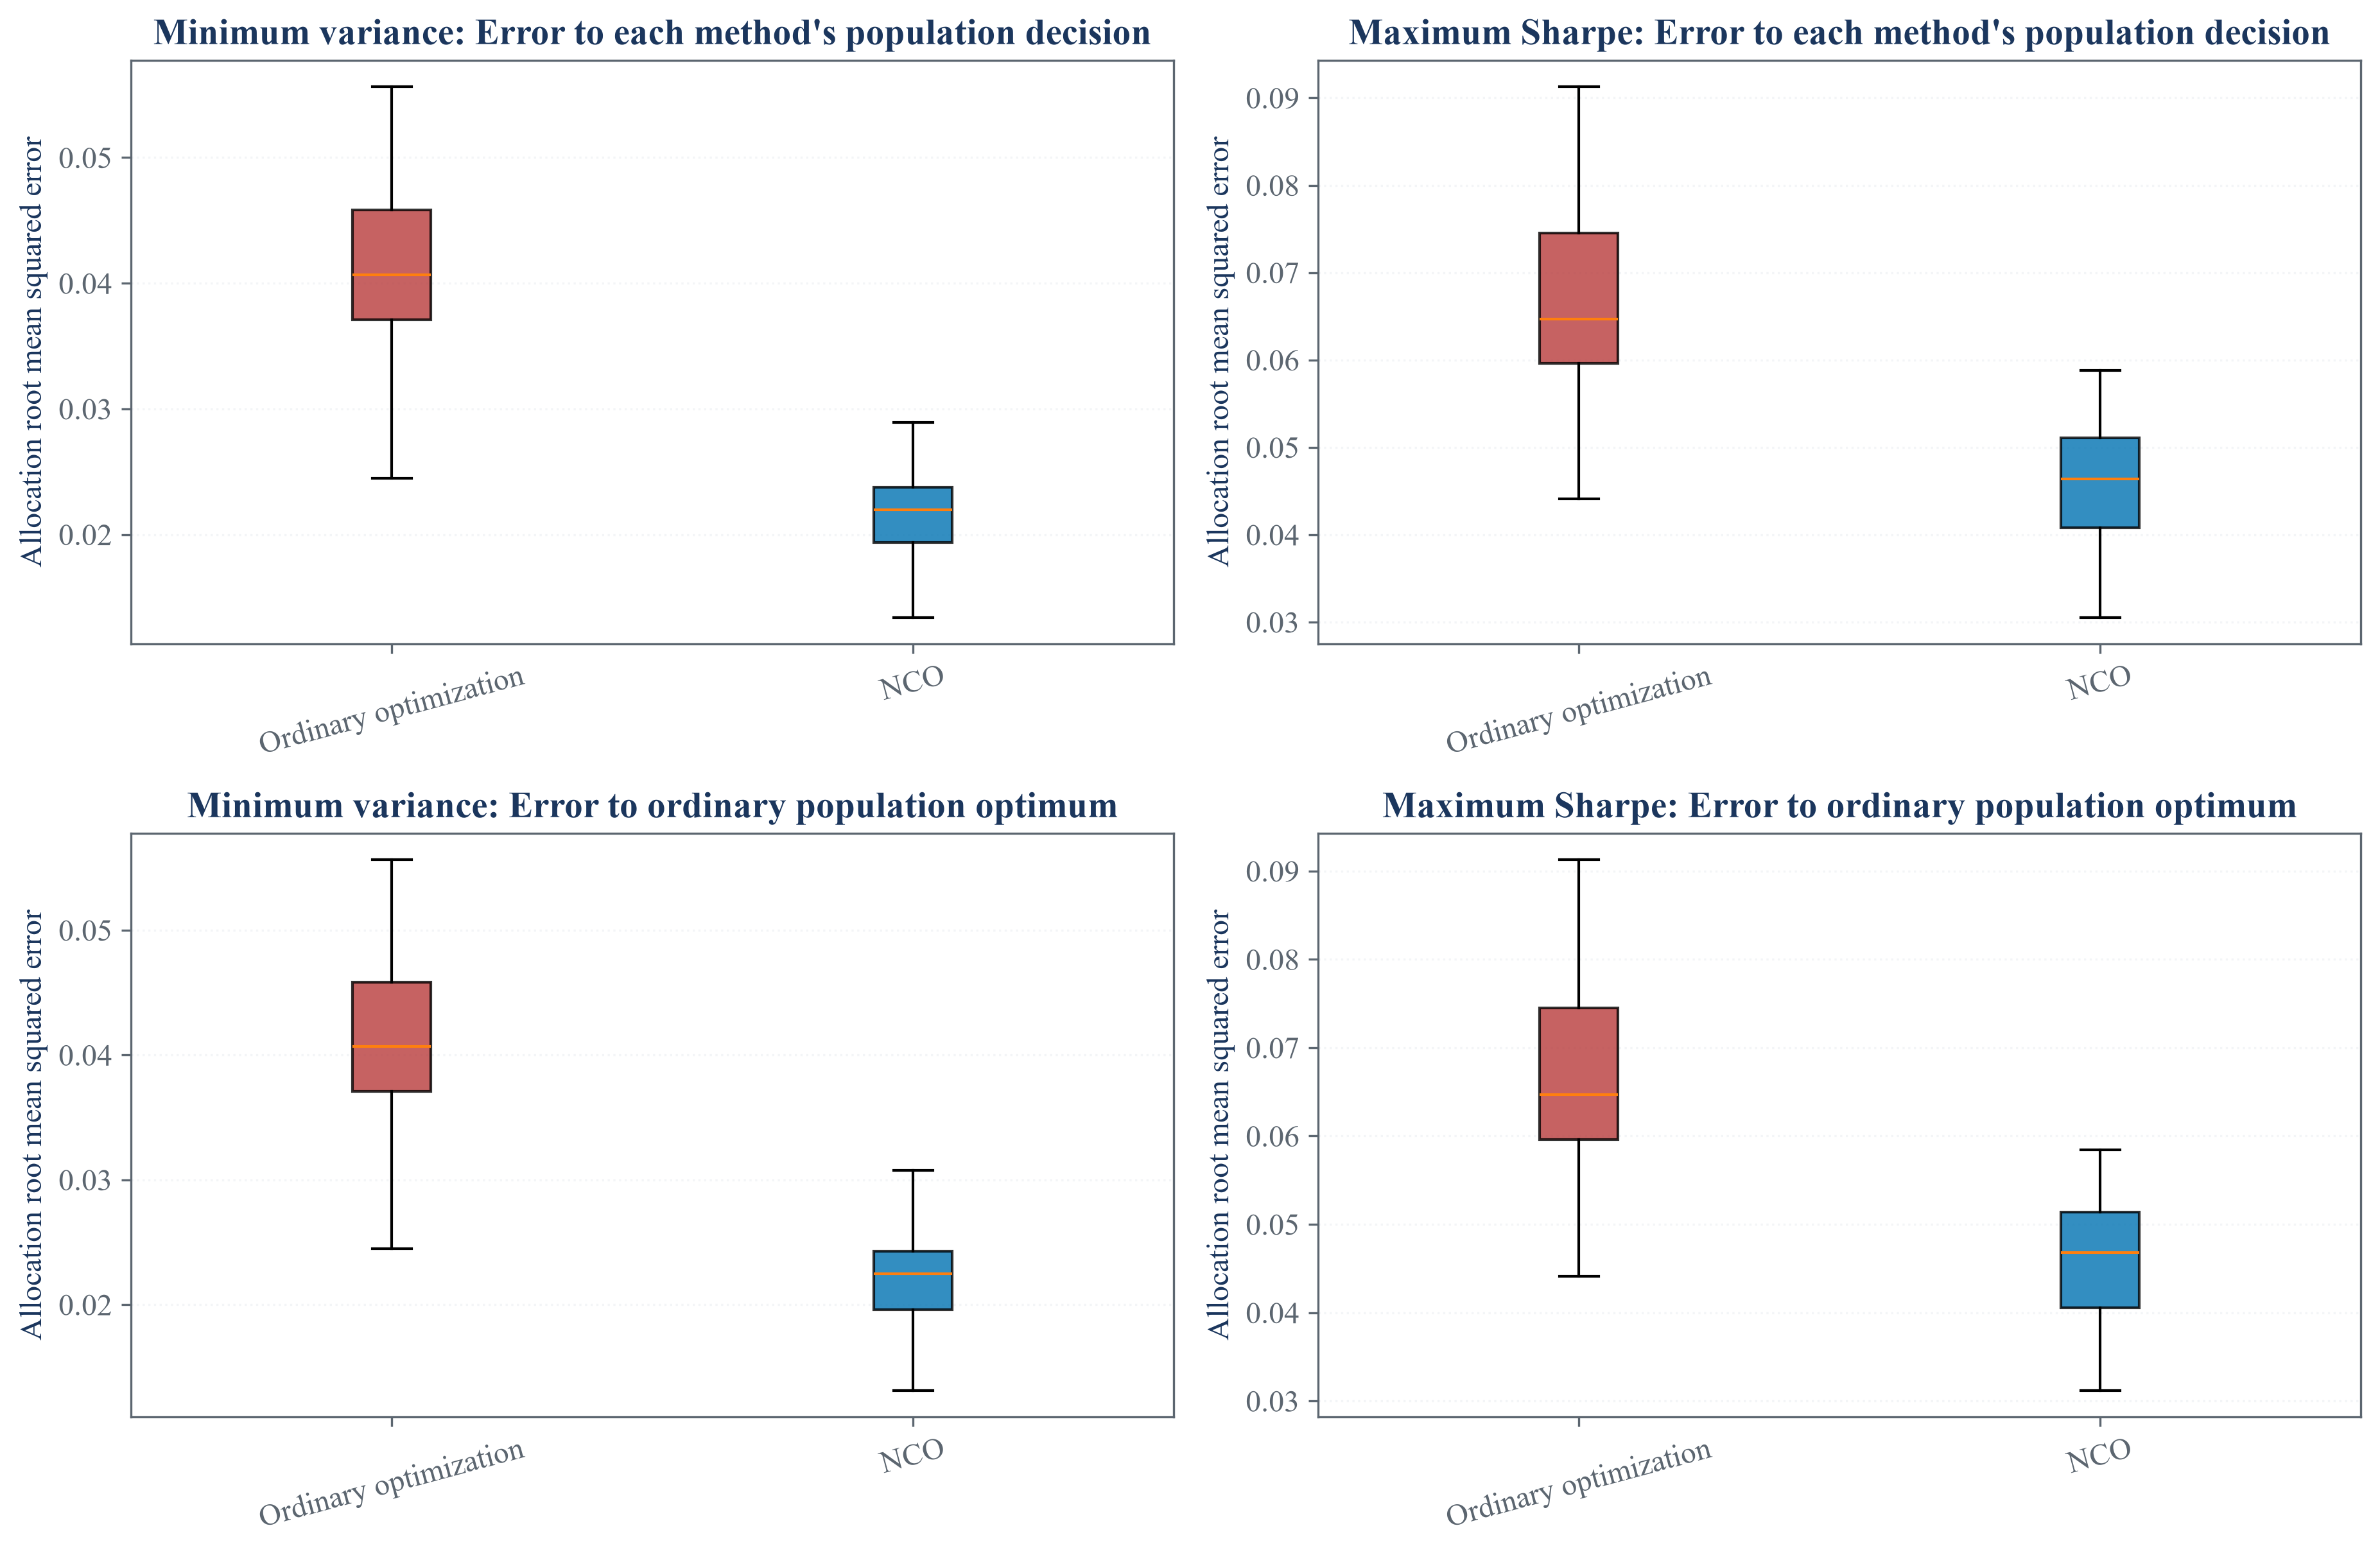

In [2]:
objective_specs = [("Minimum variance", None), ("Maximum Sharpe", true_mean)]
oracle_weights = {}
for objective_name, objective_mean in objective_specs:
    oracle_weights[(objective_name, "Ordinary optimization")] = optimal_series(true_covariance, objective_mean)
    oracle_weights[(objective_name, "NCO")] = nco_components(true_covariance, objective_mean, maximum_clusters=4, seed=2210)["final"]

repeated_rows = []
for objective_number, (objective_name, objective_mean) in enumerate(objective_specs):
    ordinary_oracle = oracle_weights[(objective_name, "Ordinary optimization")].reindex(true_covariance.index)
    for repetition in range(40):
        rng = np.random.default_rng(222000 + 1000 * objective_number + repetition)
        sample = pd.DataFrame(rng.multivariate_normal(true_mean.to_numpy(dtype=float), true_covariance.to_numpy(dtype=float), size=180), columns=true_covariance.index)
        sample_covariance = sample.cov()
        sample_mean = None if objective_mean is None else sample.mean()
        fitted = {"Ordinary optimization": optimal_series(sample_covariance, sample_mean), "NCO": nco_components(sample_covariance, sample_mean, maximum_clusters=4, seed=2210)["final"]}
        for method, weights in fitted.items():
            oracle = oracle_weights[(objective_name, method)].reindex(true_covariance.index)
            aligned = weights.reindex(true_covariance.index)
            allocation_error = float(np.sqrt(np.mean((aligned.to_numpy(dtype=float) - oracle.to_numpy(dtype=float)) ** 2)))
            ordinary_target_error = float(np.sqrt(np.mean((aligned.to_numpy(dtype=float) - ordinary_oracle.to_numpy(dtype=float)) ** 2)))
            true_variance = portfolio_variance(aligned, true_covariance)
            true_return = float(aligned @ true_mean)
            true_sharpe = true_return / np.sqrt(true_variance)
            repeated_rows.append({"Objective": objective_name, "Repetition": repetition + 1, "Method": method, "Own-decision allocation error": allocation_error, "Error to ordinary population optimum": ordinary_target_error, "True variance": true_variance, "True Sharpe ratio": true_sharpe, "Gross exposure": float(np.abs(aligned).sum()), "Weight concentration": float(aligned @ aligned)})
mcos_results = pd.DataFrame(repeated_rows)
mcos_summary = mcos_results.groupby(["Objective", "Method"], as_index=False).agg(**{"Mean own-decision error": ("Own-decision allocation error", "mean"), "Median own-decision error": ("Own-decision allocation error", "median"), "Own-decision error standard error": ("Own-decision allocation error", lambda values: values.std(ddof=1) / np.sqrt(len(values))), "Mean error to ordinary population optimum": ("Error to ordinary population optimum", "mean"), "Mean true variance": ("True variance", "mean"), "Mean true Sharpe ratio": ("True Sharpe ratio", "mean"), "Mean gross exposure": ("Gross exposure", "mean"), "Mean weight concentration": ("Weight concentration", "mean")})
error_pivot = mcos_summary.pivot(index="Objective", columns="Method", values="Mean own-decision error")
error_ratios = pd.DataFrame({"Objective": error_pivot.index, "NCO error as percent of ordinary error": 100.0 * error_pivot["NCO"] / error_pivot["Ordinary optimization"]}).reset_index(drop=True)
paper_design_results = pd.DataFrame({"Objective": ["Minimum variance", "Maximum Sharpe"], "Securities": [50, 50], "Blocks": [10, 10], "Observations": [1000, 1000], "Repetitions": [1000, 1000], "Raw NCO error as percent of ordinary error": [44.95, 42.20], "Source": ["Original 2019 NCO paper", "Original 2019 NCO paper"]})
mcos_book_summary = mcos_summary[["Objective", "Method", "Mean own-decision error", "Mean error to ordinary population optimum", "Mean true variance", "Mean true Sharpe ratio"]]
save_table(mcos_book_summary, "mcos_nco_summary", "Repeated allocation error and known-input performance summaries.", "tab:chapter22-mcos-summary")
save_table(error_ratios, "mcos_nco_error_ratios", "NCO allocation error relative to ordinary optimization in the Chapter 22 calculation.", "tab:chapter22-mcos-ratios")
save_table(paper_design_results, "original_nco_paper_results", "Design-limited allocation-error ratios reported in the original NCO paper.", "tab:chapter22-original-paper-results", float_format="%.2f")
display(mcos_summary)
display(error_ratios)
display(paper_design_results)

figure, axes = plt.subplots(2, 2, figsize=(12.5, 8.2))
method_order = ["Ordinary optimization", "NCO"]
colors = [palette["rose"], palette["cyan"]]
error_measures = [("Own-decision allocation error", "Error to each method's population decision"), ("Error to ordinary population optimum", "Error to ordinary population optimum")]
for row, (measure, row_title) in enumerate(error_measures):
    for column, objective_name in enumerate(["Minimum variance", "Maximum Sharpe"]):
        axis = axes[row, column]
        data = [mcos_results.loc[(mcos_results["Objective"] == objective_name) & (mcos_results["Method"] == method), measure] for method in method_order]
        boxes = axis.boxplot(data, tick_labels=method_order, patch_artist=True, showfliers=False)
        for patch, color in zip(boxes["boxes"], colors):
            patch.set_facecolor(color)
            patch.set_alpha(0.8)
        axis.set_title(f"{objective_name}: {row_title}")
        axis.set_ylabel("Allocation root mean squared error")
        axis.tick_params(axis="x", rotation=15)
        axis.grid(axis="y", alpha=0.3)
figure.tight_layout()
save_figure(figure, "mcos_allocation_error")

## Comparing five portfolio rules after covariance cleaning

The observations-per-asset ratio records the amount of covariance information available for each dimension:

$$
\eta=\frac{T}{N}.
$$

Here, $T$ is the number of observations, $N$ is the number of assets, and $\eta$ is smaller when covariance estimation is more difficult.

,Method,Raw known variance,Denoised known variance,Denoised-to-raw variance ratio
0,Equal weight,0.004949,0.004949,1
1,HRP,0.004081,0.004016,0.984095
2,Inverse variance,0.003993,0.003993,1
3,NCO,0.004037,0.003969,0.983347
4,Ordinary minimum variance,0.004361,0.004228,0.96933


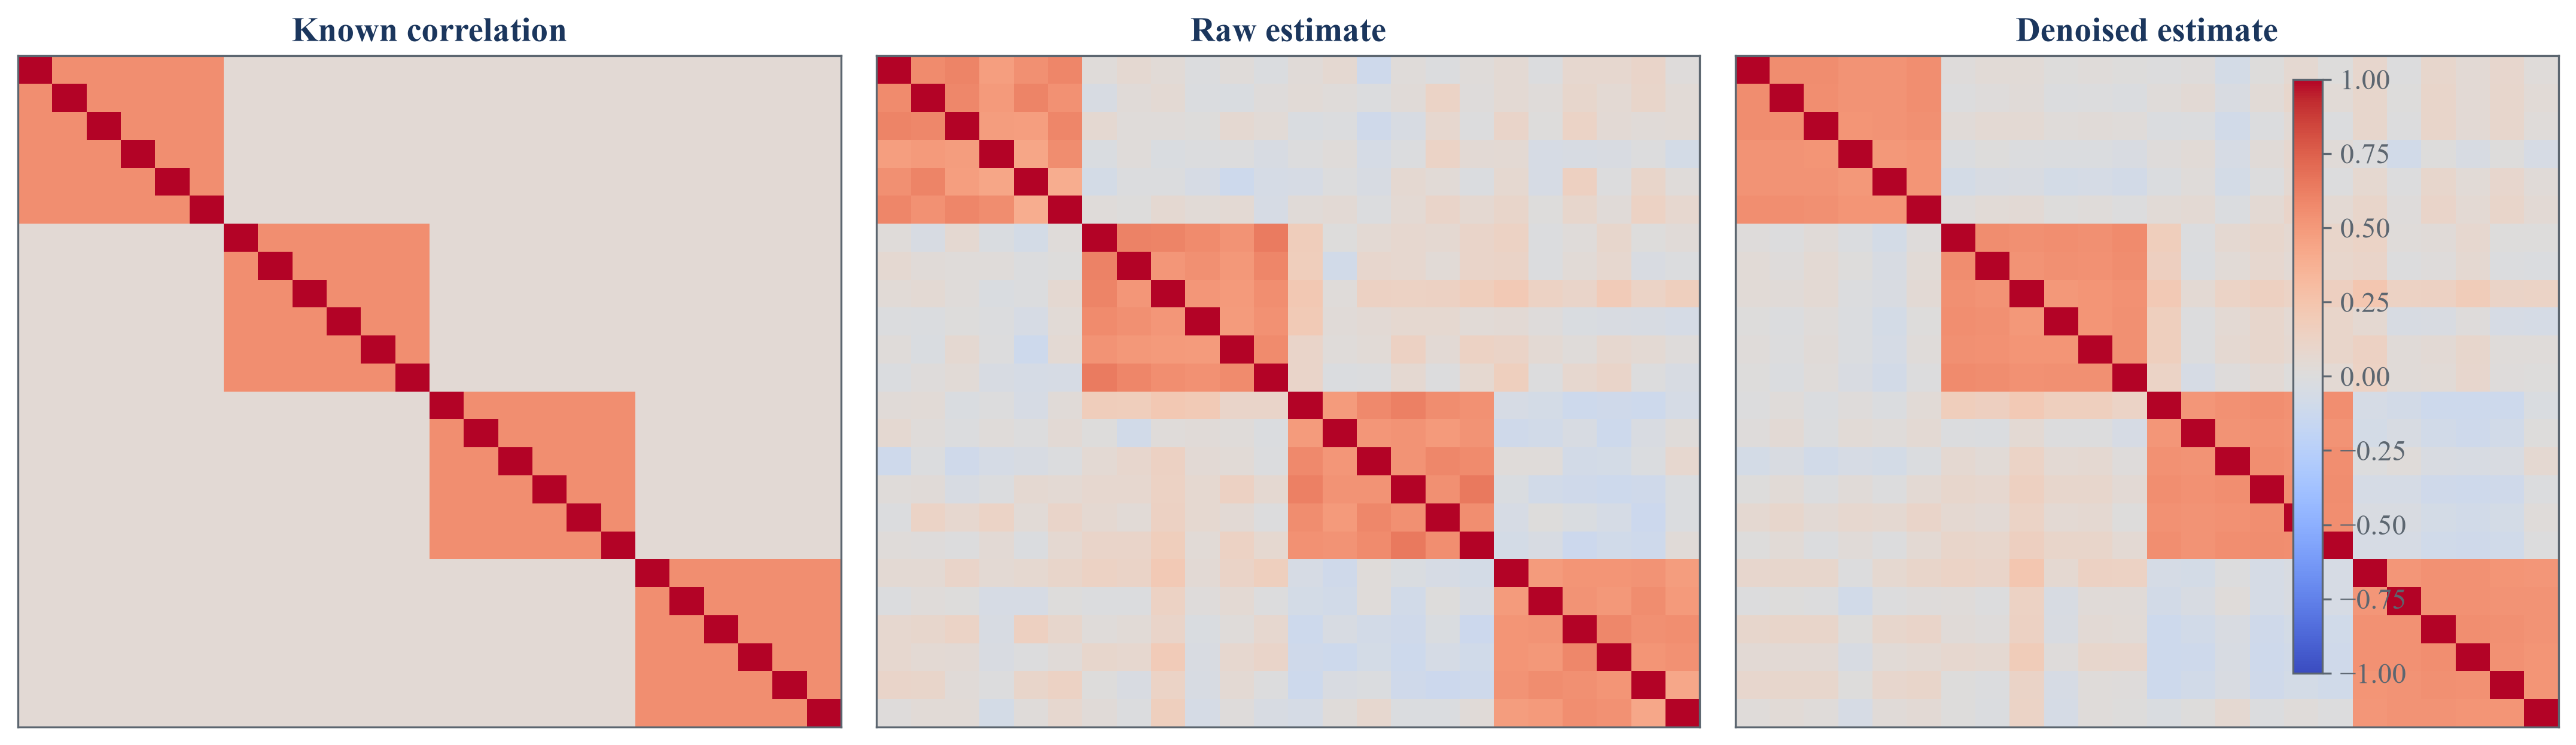

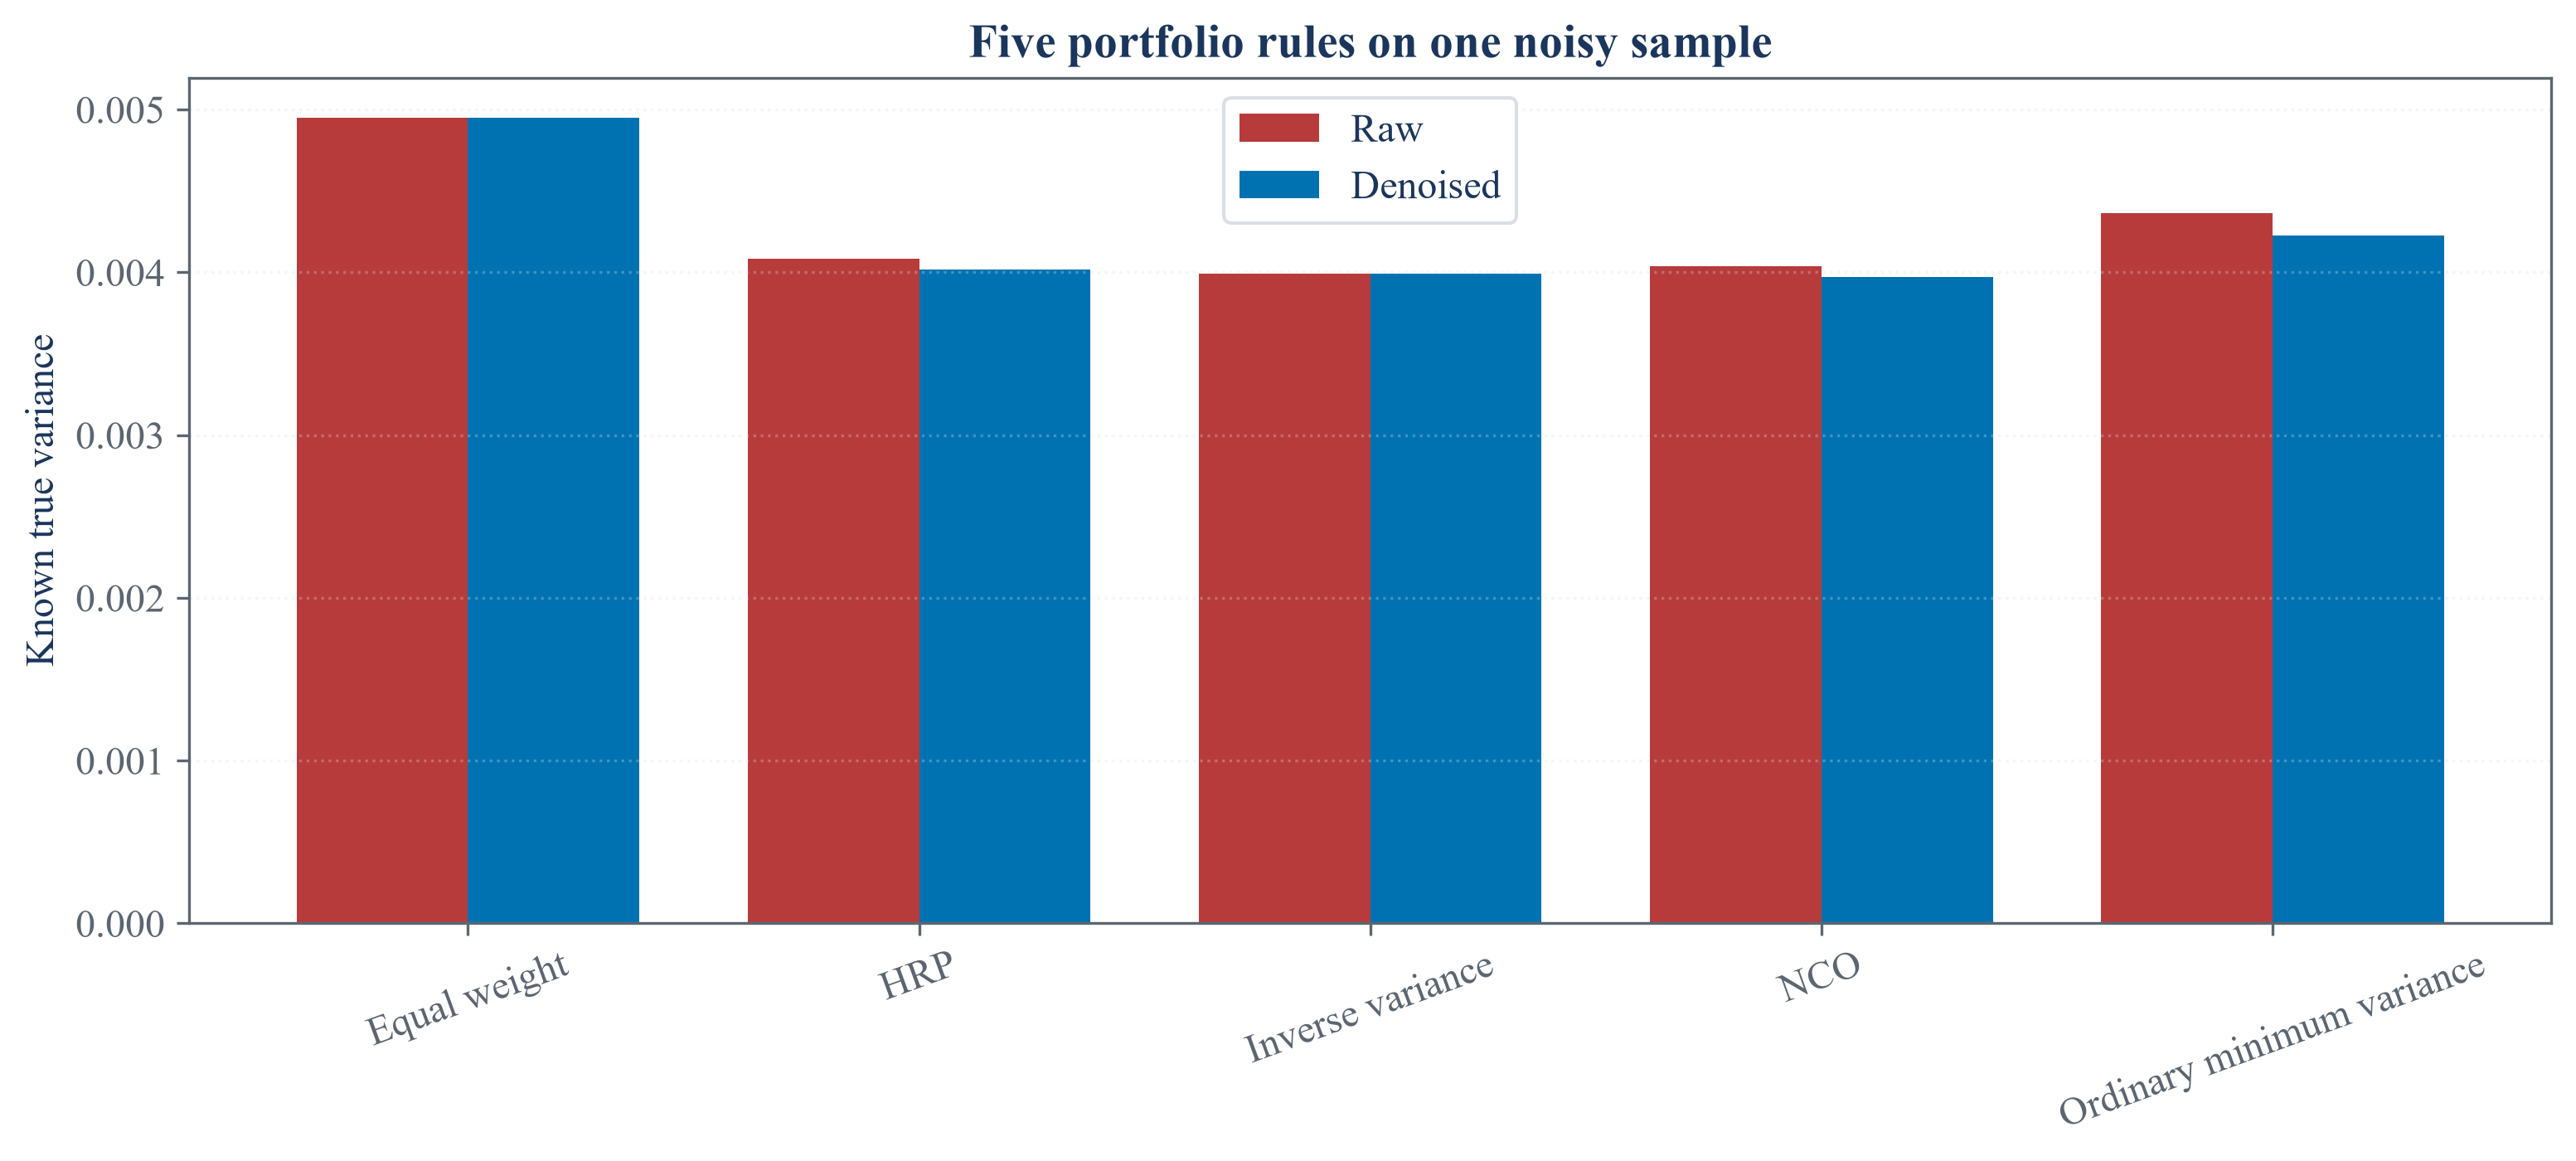

In [3]:
demonstration_denoised = pd.DataFrame(denoise_cov(demonstration_covariance.to_numpy(dtype=float), 180.0 / len(true_covariance), bandwidth=0.01), index=true_covariance.index, columns=true_covariance.columns)

def five_portfolios(covariance, seed):
    return {"Equal weight": pd.Series(1.0 / len(covariance), index=covariance.index), "Inverse variance": inverse_variance_series(covariance), "HRP": hrp_series(covariance), "Ordinary minimum variance": optimal_series(covariance), "NCO": released_nco(covariance, maximum_clusters=4, seed=seed)}

raw_portfolios = five_portfolios(demonstration_covariance, 2220)
denoised_portfolios = five_portfolios(demonstration_denoised, 2220)
denoising_rows = []
for covariance_name, portfolios in [("Raw sample covariance", raw_portfolios), ("Denoised sample covariance", denoised_portfolios)]:
    for method, weights in portfolios.items():
        denoising_rows.append({"Covariance input": covariance_name, "Method": method, "Known true variance": portfolio_variance(weights, true_covariance), "Gross exposure": float(np.abs(weights).sum()), "Weight concentration": float(weights @ weights), "Largest absolute weight": float(np.abs(weights).max())})
denoising_summary = pd.DataFrame(denoising_rows)
denoising_pivot = denoising_summary.pivot(index="Method", columns="Covariance input", values="Known true variance")
denoising_comparison = pd.DataFrame({"Method": denoising_pivot.index, "Raw known variance": denoising_pivot["Raw sample covariance"], "Denoised known variance": denoising_pivot["Denoised sample covariance"], "Denoised-to-raw variance ratio": denoising_pivot["Denoised sample covariance"] / denoising_pivot["Raw sample covariance"]}).reset_index(drop=True)
save_table(denoising_summary, "raw_denoised_portfolio_summary", "Known-input risk and weight diagnostics for raw and denoised covariance inputs.", "tab:chapter22-denoising-summary")
save_table(denoising_comparison, "raw_denoised_variance_comparison", "Known true variance before and after covariance cleaning.", "tab:chapter22-denoising-comparison")
display(denoising_comparison)

figure, axes = plt.subplots(1, 3, figsize=(14.5, 4.3))
for axis, matrix, title in zip(axes, [true_correlation, demonstration_correlation, correlation_frame(demonstration_denoised)], ["Known correlation", "Raw estimate", "Denoised estimate"]):
    image = axis.imshow(matrix.to_numpy(dtype=float), vmin=-1.0, vmax=1.0, cmap="coolwarm", aspect="auto")
    axis.set_title(title)
    axis.set_xticks([])
    axis.set_yticks([])
figure.colorbar(image, ax=axes, fraction=0.018, pad=0.02)
figure.tight_layout()
save_figure(figure, "denoising_correlation_comparison")

method_names = denoising_comparison["Method"].tolist()
positions = np.arange(len(method_names))
figure, axis = plt.subplots(figsize=(10.5, 4.8))
axis.bar(positions - 0.19, denoising_comparison["Raw known variance"], width=0.38, label="Raw", color=palette["rose"])
axis.bar(positions + 0.19, denoising_comparison["Denoised known variance"], width=0.38, label="Denoised", color=palette["cyan"])
axis.set_xticks(positions)
axis.set_xticklabels(method_names, rotation=20)
axis.set_ylabel("Known true variance")
axis.set_title("Five portfolio rules on one noisy sample")
axis.legend()
axis.grid(axis="y", alpha=0.3)
figure.tight_layout()
save_figure(figure, "denoising_true_risk_comparison")

## Testing nested optimization across sample regimes

True-risk inflation compares an estimated portfolio with the population minimum-variance benchmark:

$$
R_m^{(b)}=\frac{(\widehat w_m^{(b)})^{\mathsf T}\Sigma_0\widehat w_m^{(b)}}{(w_{\mathrm{MV}}^0)^{\mathsf T}\Sigma_0w_{\mathrm{MV}}^0}.
$$

Here, $\Sigma_0$ is the known covariance matrix, $\widehat w_m^{(b)}$ is the estimated weight vector for method $m$ in repetition $b$, $w_{\mathrm{MV}}^0$ is the population minimum-variance portfolio, and $R_m^{(b)}$ equals one at the population minimum. Each plotted mean uses ten repetitions. The shaded interval is the mean plus or minus $1.96$ estimated standard errors, so it describes simulation uncertainty in this small controlled study rather than a universal performance range.

,Within-cluster correlation,Training observations,Assets,Observations per asset,Method,Mean true-risk ratio,Median true-risk ratio,True-risk standard error,Mean gross exposure
0,0.3,80,24,3.333333,NCO,1.10755,1.078696,0.023306,1.041445
1,0.3,80,24,3.333333,Ordinary minimum variance,1.36669,1.381216,0.040297,1.272978
2,0.3,160,24,6.666667,NCO,1.062487,1.062773,0.00875,1.004629
3,0.3,160,24,6.666667,Ordinary minimum variance,1.1723,1.154306,0.018775,1.107906
4,0.3,320,24,13.333333,NCO,1.024429,1.024449,0.002885,1
5,0.3,320,24,13.333333,Ordinary minimum variance,1.081195,1.069454,0.011665,1.047478
6,0.6,80,24,3.333333,NCO,1.097159,1.083302,0.016309,1.171445
7,0.6,80,24,3.333333,Ordinary minimum variance,1.439995,1.446736,0.029275,1.871502
8,0.6,160,24,6.666667,NCO,1.053978,1.047662,0.007672,1.142334
9,0.6,160,24,6.666667,Ordinary minimum variance,1.178945,1.186068,0.021609,1.482236


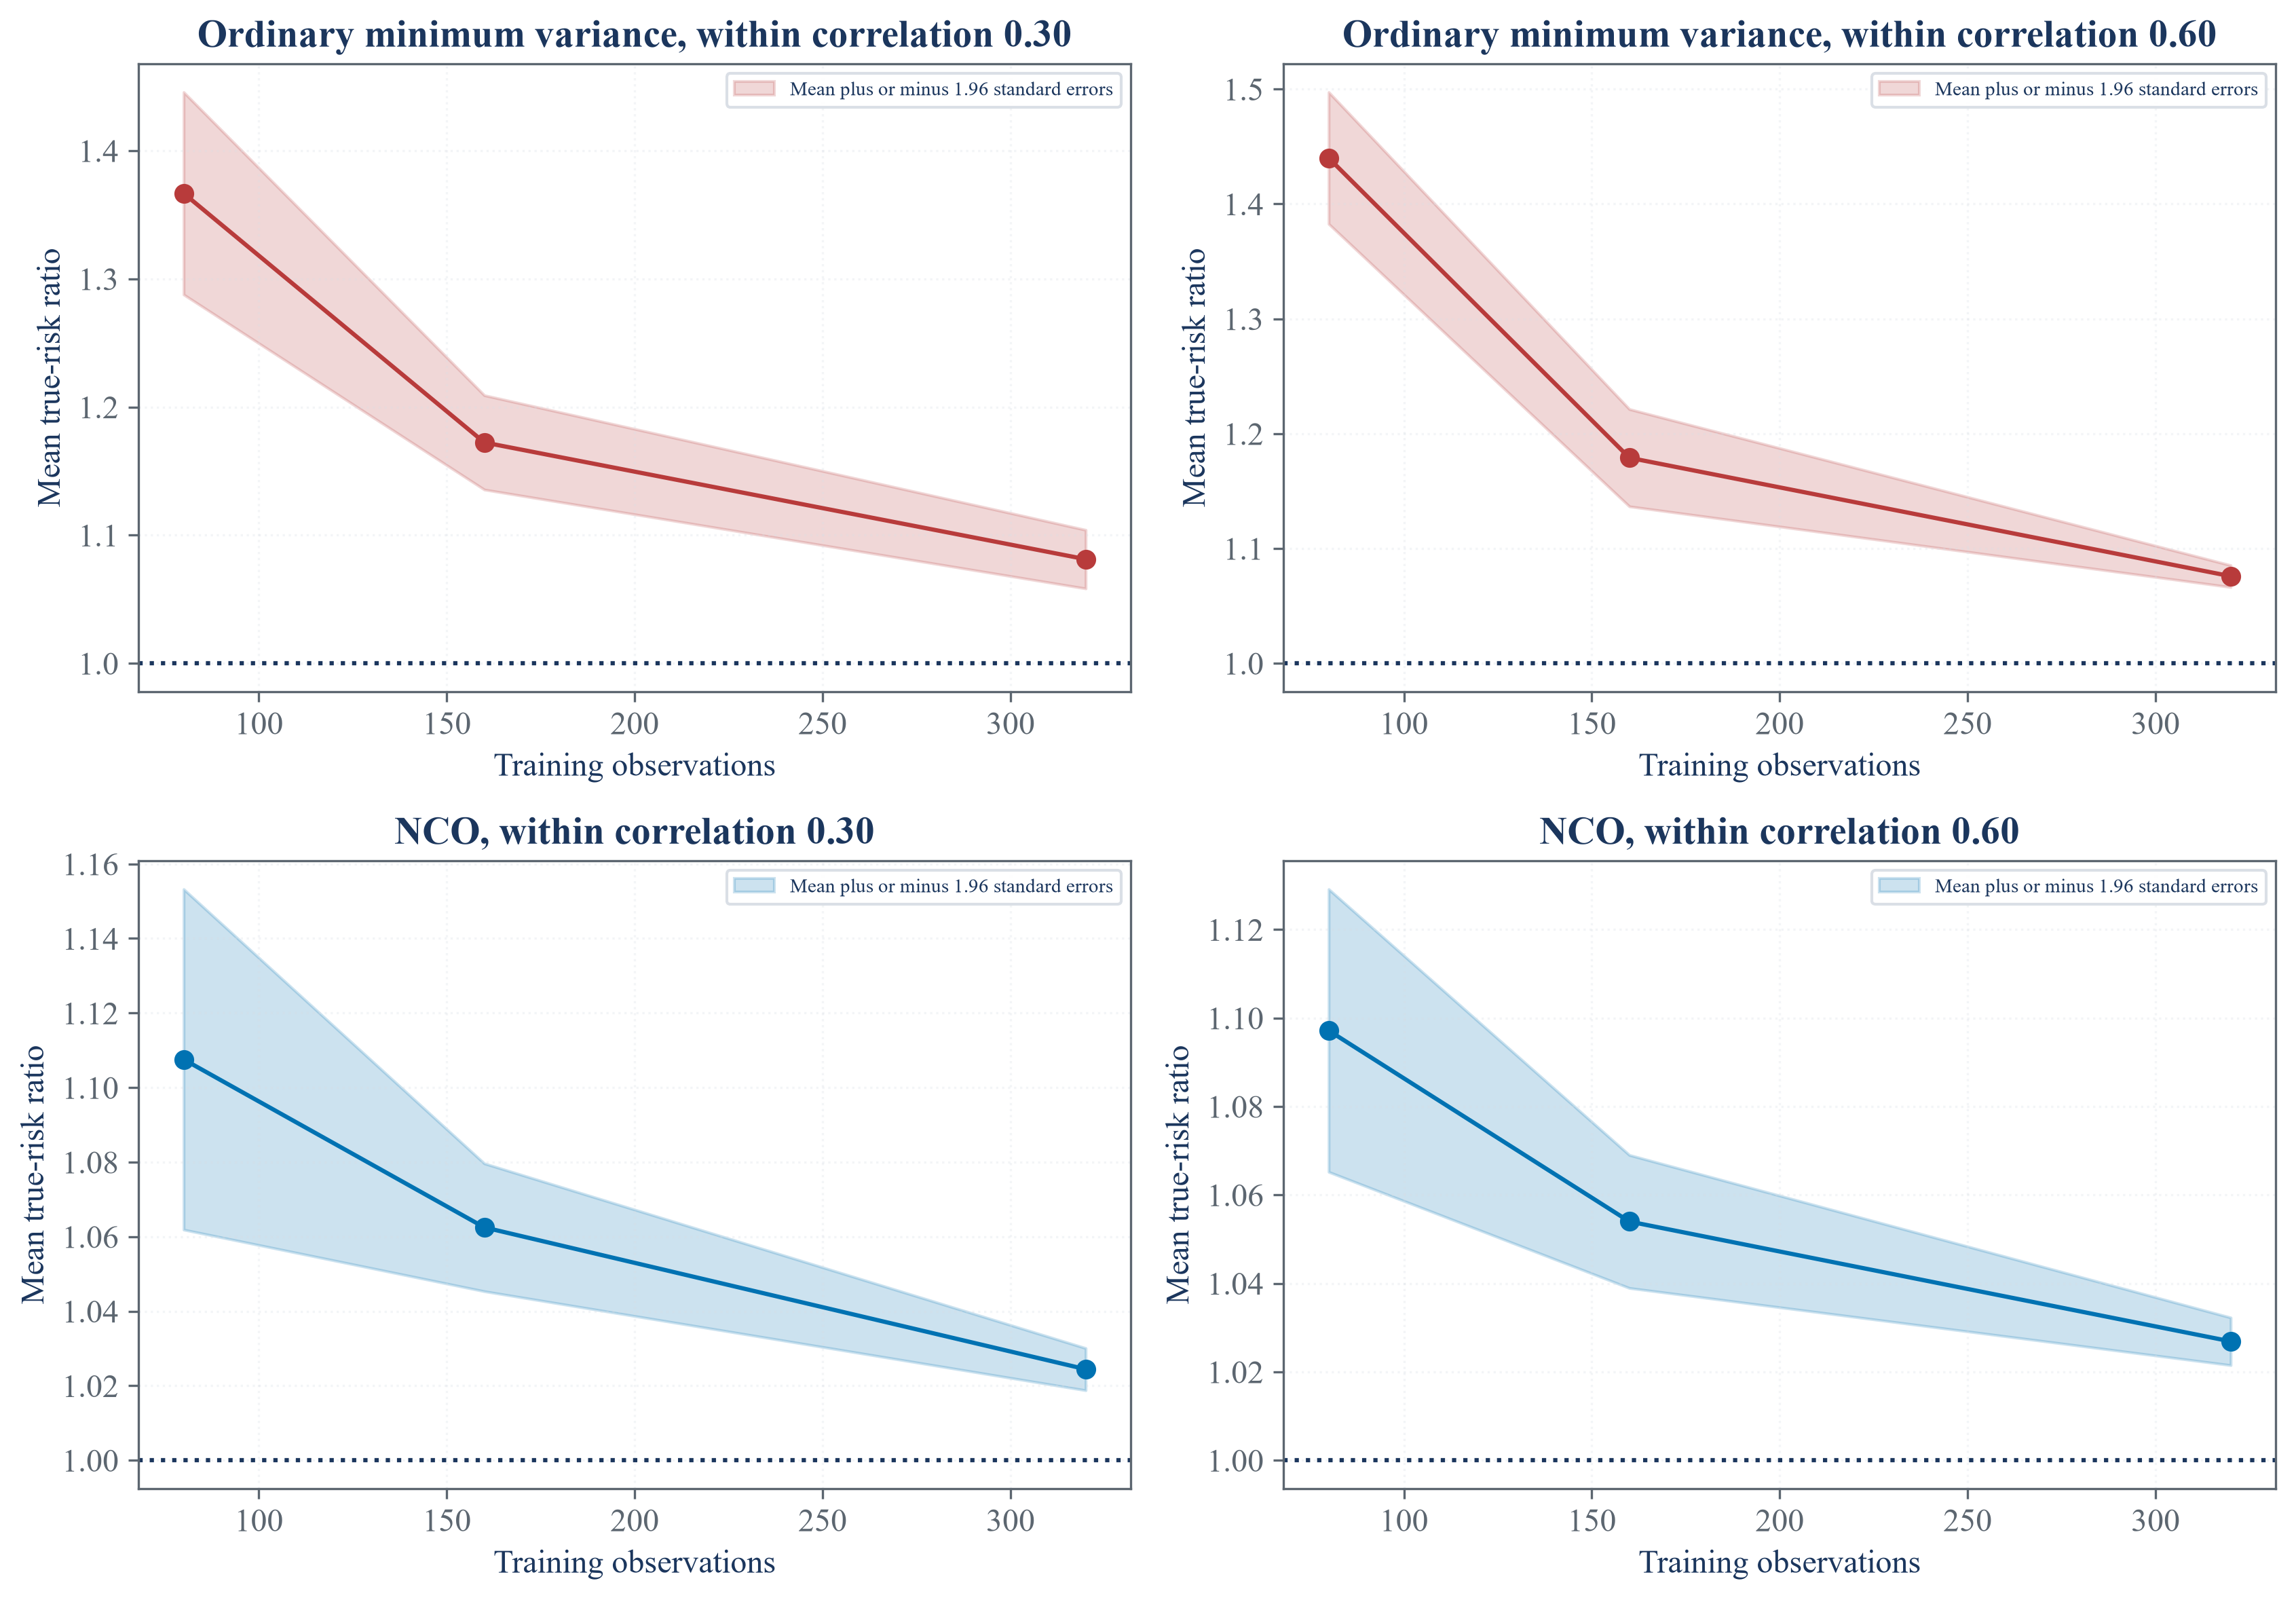

In [4]:
sensitivity_rows = []
for within_correlation in [0.30, 0.60]:
    sensitivity_covariance, sensitivity_correlation = block_covariance(4, 6, within_correlation, 0.04)
    population_minimum = optimal_series(sensitivity_covariance)
    population_variance = portfolio_variance(population_minimum, sensitivity_covariance)
    for training_observations in [80, 160, 320]:
        for repetition in range(10):
            rng = np.random.default_rng(223000 + int(within_correlation * 1000) + training_observations + repetition)
            sample = pd.DataFrame(rng.multivariate_normal(np.zeros(len(sensitivity_covariance)), sensitivity_covariance.to_numpy(dtype=float), size=training_observations), columns=sensitivity_covariance.index)
            fitted = {"Ordinary minimum variance": optimal_series(sample.cov()), "NCO": released_nco(sample.cov(), maximum_clusters=4, seed=2230)}
            for method, weights in fitted.items():
                sensitivity_rows.append({"Within-cluster correlation": within_correlation, "Training observations": training_observations, "Assets": len(sensitivity_covariance), "Observations per asset": training_observations / len(sensitivity_covariance), "Repetition": repetition + 1, "Method": method, "True-risk ratio": portfolio_variance(weights, sensitivity_covariance) / population_variance, "Gross exposure": float(np.abs(weights).sum())})
sensitivity_results = pd.DataFrame(sensitivity_rows)
sensitivity_summary = sensitivity_results.groupby(["Within-cluster correlation", "Training observations", "Assets", "Observations per asset", "Method"], as_index=False).agg(**{"Mean true-risk ratio": ("True-risk ratio", "mean"), "Median true-risk ratio": ("True-risk ratio", "median"), "True-risk standard error": ("True-risk ratio", lambda values: values.std(ddof=1) / np.sqrt(len(values))), "Mean gross exposure": ("Gross exposure", "mean")})
sensitivity_book_summary = sensitivity_summary[["Within-cluster correlation", "Observations per asset", "Method", "Mean true-risk ratio", "True-risk standard error", "Mean gross exposure"]]
save_table(sensitivity_book_summary, "nco_sampling_sensitivity", "Known-covariance sensitivity to sample size and cluster strength.", "tab:chapter22-sensitivity")
display(sensitivity_summary)

figure, axes = plt.subplots(2, 2, figsize=(11.5, 8))
for row, method in enumerate(["Ordinary minimum variance", "NCO"]):
    for column, within_correlation in enumerate([0.30, 0.60]):
        subset = sensitivity_summary[(sensitivity_summary["Method"] == method) & (sensitivity_summary["Within-cluster correlation"] == within_correlation)].sort_values("Training observations")
        axes[row, column].plot(subset["Training observations"], subset["Mean true-risk ratio"], marker="o", color=palette["rose"] if method.startswith("Ordinary") else palette["cyan"])
        axes[row, column].fill_between(subset["Training observations"], subset["Mean true-risk ratio"] - 1.96 * subset["True-risk standard error"], subset["Mean true-risk ratio"] + 1.96 * subset["True-risk standard error"], alpha=0.2, color=palette["rose"] if method.startswith("Ordinary") else palette["cyan"], label="Mean plus or minus 1.96 standard errors")
        axes[row, column].axhline(1.0, color=palette["text"], linestyle=":")
        axes[row, column].set_title(f"{method}, within correlation {within_correlation:.2f}")
        axes[row, column].set_xlabel("Training observations")
        axes[row, column].set_ylabel("Mean true-risk ratio")
        axes[row, column].grid(alpha=0.3)
        axes[row, column].legend(fontsize=7)
figure.tight_layout()
save_figure(figure, "nco_sampling_sensitivity")

## A Conditional Bridge to Global Minimum Variance

Cotton's bridge changes both the covariance used inside each cluster and the direction that accompanies it before the final allocation across clusters:

$$
\begin{aligned}
Q_g(\gamma)&=\Sigma_{gg}-\gamma\Sigma_{g,P_{-g}}\Sigma_{P_{-g},P_{-g}}^{-1}\Sigma_{P_{-g},g},\\
b_g(\gamma)&=\mathbf 1_g-\gamma\Sigma_{g,P_{-g}}\Sigma_{P_{-g},P_{-g}}^{-1}\mathbf 1_{P_{-g}},\\
d_g(\gamma)&=Q_g(\gamma)^{-1}b_g(\gamma),\\
\widetilde w_\gamma&=D_\gamma(D_\gamma^{\mathsf T}\Sigma D_\gamma)^{-1}D_\gamma^{\mathsf T}\mathbf 1,
\qquad
w_\gamma=\frac{\widetilde w_\gamma}{\mathbf 1^{\mathsf T}\widetilde w_\gamma}.
\end{aligned}
$$

Here, $g$ labels a cluster, $P_{-g}$ contains one chosen representative, called a knot, from every other cluster, $\Sigma_{g,P_{-g}}$ is the covariance between cluster $g$ and those knots, $\mathbf 1_g$ and $\mathbf 1_{P_{-g}}$ are vectors of ones of the required sizes, and $0\leq\gamma\leq1$ controls how much outside information is used. The matrix $Q_g(\gamma)$ is the adjusted covariance, $b_g(\gamma)$ is its companion direction, $d_g(\gamma)$ is the unscaled direction inside cluster $g$, and $D_\gamma$ places all cluster directions in separate columns. The vector $\widetilde w_\gamma$ is the unscaled outer allocation and $w_\gamma$ is its fully invested form. At $\gamma=0$ this is NCO. At $\gamma=1$ it equals global minimum variance only under the paper's strong gateway condition, which requires each cluster member's residual after projection on its own knot to be uncorrelated with every asset outside that cluster. Clustering alone does not give this condition.

,Gamma,A knot,A member,B knot,B member,Variance,Max gap to global minimum
0,0,0.074529,0.558966,-0.082277,0.448781,0.021107,0.10971
1,0.25,0.062624,0.56988,-0.10468,0.472176,0.020952,0.087307
2,0.5,0.049762,0.583105,-0.130248,0.497381,0.020817,0.061738
3,0.75,0.035735,0.599514,-0.159299,0.52405,0.020718,0.032687
4,1,0.020224,0.620345,-0.191986,0.551418,0.020678,0


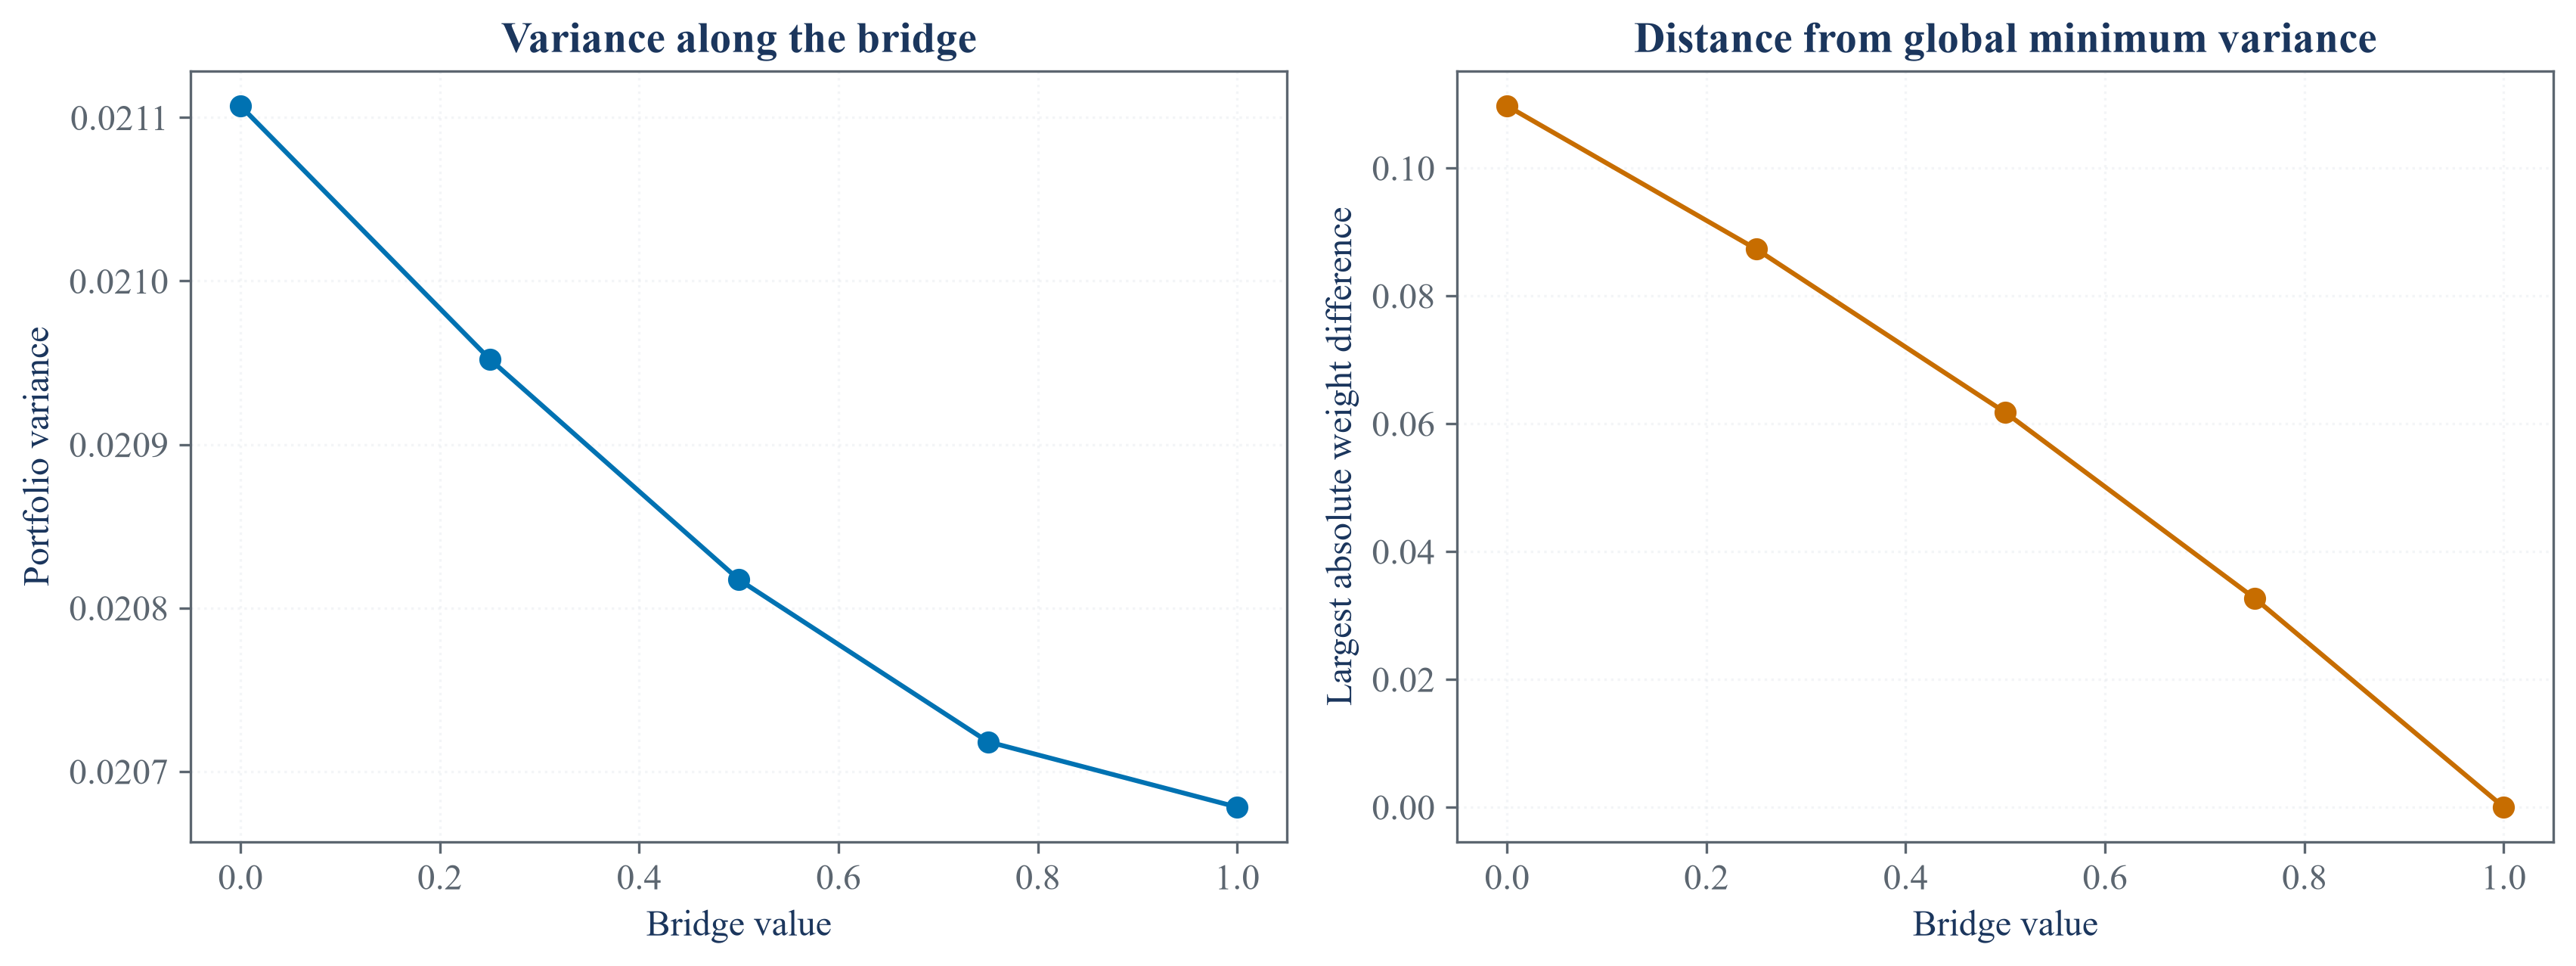

In [5]:
bridge_labels = ["Cluster A knot", "Cluster A member", "Cluster B knot", "Cluster B member"]
bridge_covariance = pd.DataFrame([[0.0400, 0.0280, 0.0180, 0.0108], [0.0280, 0.0296, 0.0126, 0.00756], [0.0180, 0.0126, 0.0900, 0.0540], [0.0108, 0.00756, 0.0540, 0.0474]], index=bridge_labels, columns=bridge_labels)
bridge_clusters = [np.array([0, 1]), np.array([2, 3])]
bridge_knots = [0, 2]
bridge_values = bridge_covariance.to_numpy(dtype=float)
bridge_ones = np.ones(len(bridge_covariance))

def schur_bridge_weights(gamma):
    direction_matrix = np.zeros((len(bridge_covariance), len(bridge_clusters)))
    for cluster_number, members in enumerate(bridge_clusters):
        other_knots = np.array([knot for number, knot in enumerate(bridge_knots) if number != cluster_number])
        cluster_block = bridge_values[np.ix_(members, members)]
        cross_block = bridge_values[np.ix_(members, other_knots)]
        knot_block = bridge_values[np.ix_(other_knots, other_knots)]
        adjusted_covariance = cluster_block - gamma * cross_block @ np.linalg.solve(knot_block, cross_block.T)
        adjusted_direction = np.ones(len(members)) - gamma * cross_block @ np.linalg.solve(knot_block, np.ones(len(other_knots)))
        direction_matrix[members, cluster_number] = np.linalg.solve(adjusted_covariance, adjusted_direction)
    outer_direction = np.linalg.solve(direction_matrix.T @ bridge_values @ direction_matrix, direction_matrix.T @ bridge_ones)
    unscaled = direction_matrix @ outer_direction
    return pd.Series(unscaled / unscaled.sum(), index=bridge_labels)

bridge_within = np.zeros((len(bridge_covariance), len(bridge_clusters)))
for cluster_number, members in enumerate(bridge_clusters):
    local_block = pd.DataFrame(bridge_values[np.ix_(members, members)], index=np.array(bridge_labels)[members], columns=np.array(bridge_labels)[members])
    bridge_within[members, cluster_number] = optimal_series(local_block).to_numpy(dtype=float)
bridge_reduced = bridge_within.T @ bridge_values @ bridge_within
bridge_between = np.linalg.solve(bridge_reduced, np.ones(len(bridge_clusters)))
bridge_between = bridge_between / bridge_between.sum()
prescribed_nco = pd.Series(bridge_within @ bridge_between, index=bridge_labels)
global_minimum = optimal_series(bridge_covariance)
bridge_rows = []
for gamma in np.linspace(0.0, 1.0, 5):
    weights = schur_bridge_weights(gamma)
    bridge_rows.append({"Gamma": gamma, "A knot": weights.loc[bridge_labels[0]], "A member": weights.loc[bridge_labels[1]], "B knot": weights.loc[bridge_labels[2]], "B member": weights.loc[bridge_labels[3]], "Variance": portfolio_variance(weights, bridge_covariance), "Max gap to global minimum": float(np.abs(weights - global_minimum).max())})
bridge_example = pd.DataFrame(bridge_rows)
save_table(bridge_example, "schur_bridge_example", "A two-cluster bridge under the gateway condition.", "tab:chapter22-schur-example", position="H")
display(bridge_example)

figure, axes = plt.subplots(1, 2, figsize=(11.5, 4.4))
axes[0].plot(bridge_example["Gamma"], bridge_example["Variance"], marker="o", color=palette["cyan"])
axes[0].set_title("Variance along the bridge")
axes[0].set_ylabel("Portfolio variance")
axes[1].plot(bridge_example["Gamma"], bridge_example["Max gap to global minimum"], marker="o", color=palette["amber"])
axes[1].set_title("Distance from global minimum variance")
axes[1].set_ylabel("Largest absolute weight difference")
for axis in axes:
    axis.set_xlabel("Bridge value")
    axis.grid(alpha=0.3)
figure.tight_layout()
save_figure(figure, "schur_bridge_example")

## Controlled Timing Demonstration

This controlled example repeats the same small independent calculation with a fixed $0.03$-second wait. It measures how elapsed time changes when independent calculations are arranged together. It does not measure NCO speed. A measured time ratio compares doing the calculations one at a time with doing $p$ at the same time:

$$
S_p=\frac{t_{1}}{t_p}.
$$

Here, $t_1$ is elapsed time when the calculations are done one at a time, $t_p$ is elapsed time when up to $p$ calculations are done at once, and $S_p$ is a machine-specific timing result rather than a mathematical guarantee.

,Execution form,Calculations at once,Independent calculations,Elapsed seconds,One-at-a-time time ratio,Results match
0,One at a time,1,20,0.614169,1,Yes
1,Two at a time,2,20,0.580443,1.058105,Yes
2,Two at a time in groups,2,20,0.31158,1.971145,Yes


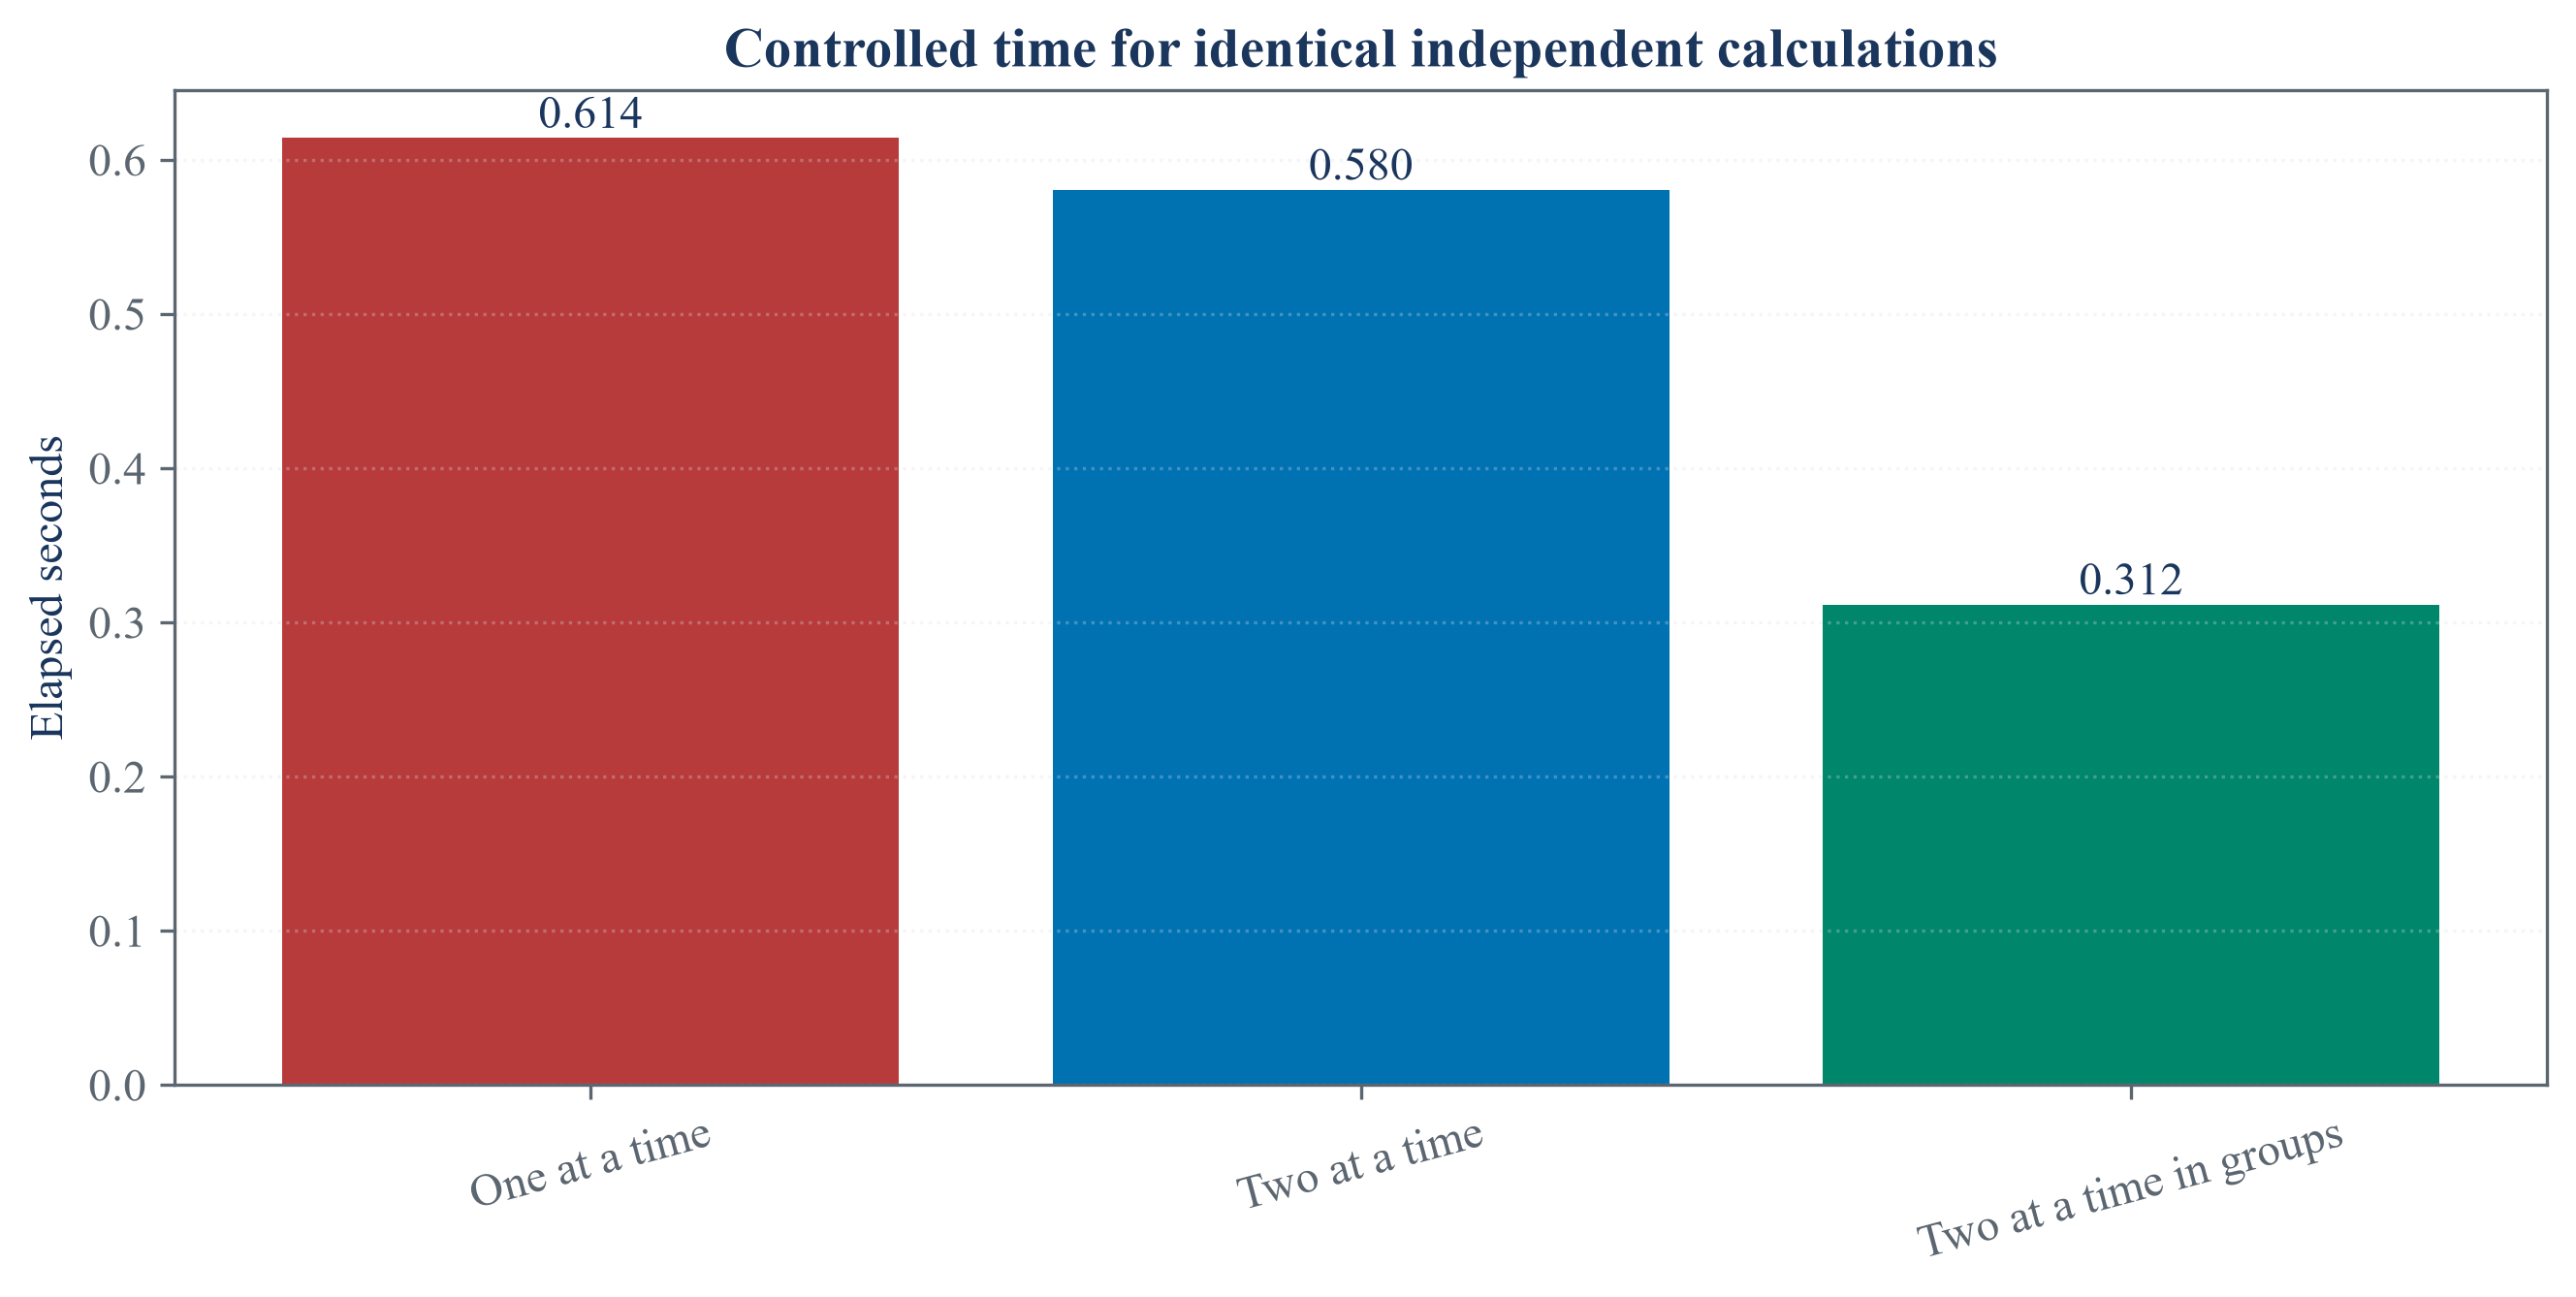

In [6]:
timing_jobs = list(range(20))

def independent_job(job):
    time.sleep(0.03)
    rng = np.random.default_rng(224000 + int(job))
    values = rng.normal(size=2000)
    return float(np.mean(values ** 2))

def chunked_jobs(indices):
    return [independent_job(int(index)) for index in indices]

serial_start = time.perf_counter()
serial_results = [independent_job(job) for job in timing_jobs]
serial_elapsed = time.perf_counter() - serial_start
item_start = time.perf_counter()
item_results = parallel_run(independent_job, timing_jobs, num_cpus=2, lin_partition=False)
item_elapsed = time.perf_counter() - item_start
chunk_start = time.perf_counter()
chunk_results = parallel_run(chunked_jobs, timing_jobs, num_cpus=2, lin_partition=True)
chunk_elapsed = time.perf_counter() - chunk_start
timing_summary = pd.DataFrame({"Execution form": ["One at a time", "Two at a time", "Two at a time in groups"], "Calculations at once": [1, 2, 2], "Independent calculations": [len(timing_jobs)] * 3, "Elapsed seconds": [serial_elapsed, item_elapsed, chunk_elapsed], "One-at-a-time time ratio": [1.0, serial_elapsed / item_elapsed, serial_elapsed / chunk_elapsed], "Results match": ["Yes", "Yes" if np.allclose(serial_results, item_results) else "No", "Yes" if np.allclose(serial_results, chunk_results) else "No"]})
save_table(timing_summary, "independent_execution_timing", "Measured time and result equality for a controlled independent calculation.", "tab:chapter22-execution-timing")
display(timing_summary)

figure, axis = plt.subplots(figsize=(9, 4.6))
bars = axis.bar(timing_summary["Execution form"], timing_summary["Elapsed seconds"], color=[palette["rose"], palette["cyan"], palette["green"]])
axis.bar_label(bars, fmt="%.3f")
axis.set_title("Controlled time for identical independent calculations")
axis.set_ylabel("Elapsed seconds")
axis.tick_params(axis="x", rotation=15)
axis.grid(axis="y", alpha=0.3)
figure.tight_layout()
save_figure(figure, "serial_parallel_execution")

## Chronological Public Comparison

Held-out volatility and one-way turnover measure different parts of a rolling allocation:

$$
\widehat\sigma_{k,m}^{\mathrm{test}}=\sqrt{252}\,\operatorname{sd}(R_k^{\mathrm{test}}w_{k,m}),
\qquad
\operatorname{TO}_{k,m}=\frac{1}{2}\lVert w_{k,m}-w_{k-1,m}\rVert_1.
$$

Here, $k$ labels a chronological window, $m$ labels a portfolio rule, $R_k^{\mathrm{test}}$ is the held-out return matrix, $w_{k,m}$ is fitted on earlier observations, and $\operatorname{sd}$ is sample standard deviation. The factor $252$ is the assumed number of trading days in one year. The notation $\lVert x\rVert_1$ means the sum of the absolute entries of $x$. Dividing by two counts the matching sale and purchase sides of one rebalance once. The turnover measure $\operatorname{TO}_{k,m}$ excludes trading costs.

,Quantity,Value
0,Assets,16
1,Training observations,252
2,Held-out observations,63
3,Window step,126
4,Windows,12
5,Portfolio rules,5
6,Trading costs included,No


,Method,Mean held-out volatility,Median held-out volatility,Mean one-way turnover,Mean gross exposure,Median weight concentration,Lowest-volatility folds
0,Equal weight,0.175816,0.152221,0,1,0.0625,0
1,HRP,0.158888,0.136445,0.086554,1,0.076833,1
2,Inverse variance,0.158456,0.136188,0.062056,1,0.076784,3
3,NCO,0.15577,0.133193,0.589027,1.699693,0.23737,2
4,Ordinary minimum variance,0.155934,0.134634,0.668246,1.970733,0.341411,6


,Preliminary experiment,Chapter 22 location,Status
0,Block-correlation condition numbers,Section 22.1,Included
1,Public covariance cleaning and clustering,Sections 22.1 and 22.2,Included
2,Within-cluster optimization,Section 22.1,Included
3,Reduced cluster covariance,Section 22.1,Included
4,Between-cluster optimization,Section 22.1,Included
5,Direct library NCO call,Section 22.1,Included
6,Own-decision allocation error,Section 22.2,Included
7,Error to the ordinary population optimum,Section 22.2,Included
8,Maximum-Sharpe allocation error,Section 22.2,Included
9,Five-rule raw and denoised comparison,Section 22.2,Included


,Quantity,Value
0,Known-input objectives,2
1,Independent repeated samples,80
2,Sensitivity method results,120
3,Public rolling windows,12
4,Compared public rules,5
5,Public observations,1760


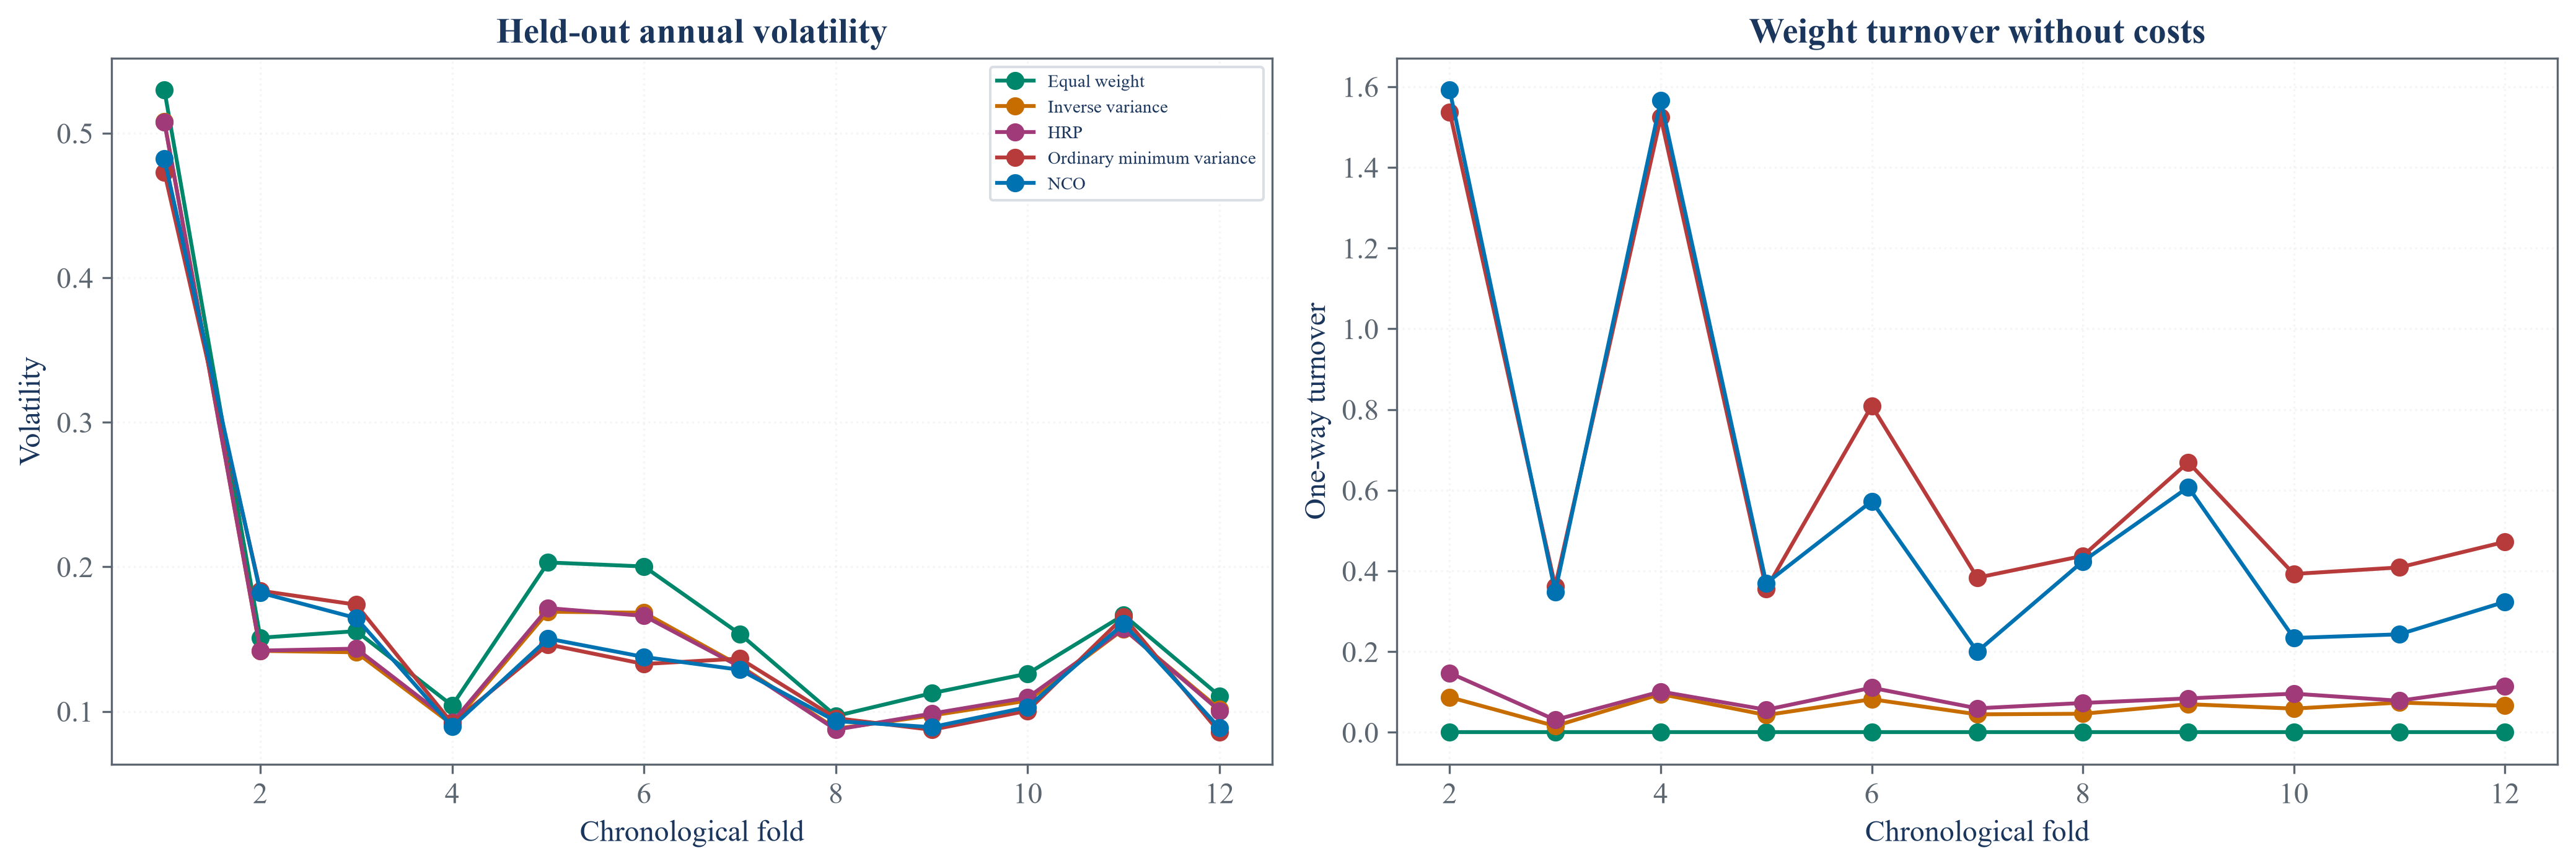

In [7]:
rolling_rows = []
previous_weights = {}
fold = 0
public_method_order = ["Equal weight", "Inverse variance", "HRP", "Ordinary minimum variance", "NCO"]
for training_end in range(251, len(public_sample) - 63, 126):
    training = public_sample.iloc[training_end - 251:training_end + 1]
    testing = public_sample.iloc[training_end + 1:training_end + 64]
    covariance = training.cov() * 252.0
    fitted = {"Equal weight": pd.Series(1.0 / len(covariance), index=covariance.index), "Inverse variance": inverse_variance_series(covariance), "HRP": hrp_series(covariance), "Ordinary minimum variance": optimal_series(covariance), "NCO": released_nco(covariance, maximum_clusters=4, seed=2250)}
    fold += 1
    for method, weights in fitted.items():
        held_out = testing.to_numpy(dtype=float) @ weights.reindex(testing.columns).to_numpy(dtype=float)
        turnover = np.nan if method not in previous_weights else one_way_turnover(weights, previous_weights[method])
        rolling_rows.append({"Fold": fold, "Training end": str(training.index[-1].date()), "Test end": str(testing.index[-1].date()), "Method": method, "Held-out annual volatility": float(np.std(held_out, ddof=1) * np.sqrt(252.0)), "One-way turnover": turnover, "Gross exposure": float(np.abs(weights).sum()), "Weight concentration": float(weights @ weights)})
        previous_weights[method] = weights
public_rolling = pd.DataFrame(rolling_rows)
rolling_summary = public_rolling.groupby("Method", as_index=False).agg(**{"Mean held-out volatility": ("Held-out annual volatility", "mean"), "Median held-out volatility": ("Held-out annual volatility", "median"), "Mean one-way turnover": ("One-way turnover", "mean"), "Mean gross exposure": ("Gross exposure", "mean"), "Median weight concentration": ("Weight concentration", "median")})
rolling_winners = public_rolling.loc[public_rolling.groupby("Fold")["Held-out annual volatility"].idxmin(), "Method"].value_counts()
rolling_summary["Lowest-volatility folds"] = rolling_summary["Method"].map(rolling_winners).fillna(0).astype(int)
rolling_design = pd.DataFrame({"Quantity": ["Assets", "Training observations", "Held-out observations", "Window step", "Windows", "Portfolio rules", "Trading costs included"], "Value": [len(selected_assets), 252, 63, 126, fold, len(public_method_order), "No"]})
preliminary_parity = pd.DataFrame({"Preliminary experiment": ["Block-correlation condition numbers", "Public covariance cleaning and clustering", "Within-cluster optimization", "Reduced cluster covariance", "Between-cluster optimization", "Direct library NCO call", "Own-decision allocation error", "Error to the ordinary population optimum", "Maximum-Sharpe allocation error", "Five-rule raw and denoised comparison", "One-at-a-time and grouped execution"], "Chapter 22 location": ["Section 22.1", "Sections 22.1 and 22.2", "Section 22.1", "Section 22.1", "Section 22.1", "Section 22.1", "Section 22.2", "Section 22.2", "Section 22.2", "Section 22.2", "Section 22.2"], "Status": ["Included"] * 11})
section_summary = pd.DataFrame({"Quantity": ["Known-input objectives", "Independent repeated samples", "Sensitivity method results", "Public rolling windows", "Compared public rules", "Public observations"], "Value": [2, len(objective_specs) * 40, len(sensitivity_results), fold, len(public_method_order), len(public_sample)]})
save_table(rolling_design, "public_nco_rolling_design", "Chronological public NCO comparison design.", "tab:chapter22-public-rolling-design")
rolling_book_summary = rolling_summary[["Method", "Mean held-out volatility", "Mean one-way turnover", "Mean gross exposure", "Lowest-volatility folds"]]
save_table(rolling_book_summary, "public_nco_rolling_summary", "Held-out public risk, turnover, and exposure summaries.", "tab:chapter22-public-rolling-summary")
save_table(preliminary_parity, "preliminary_nco_parity", "Coverage of preliminary NCO and execution experiments.", "tab:chapter22-preliminary-parity")
save_table(section_summary, "estimation_error_section_summary", "Section 22.2 numerical summary.", "tab:chapter22-estimation-section-summary")
display(rolling_design)
display(rolling_summary)
display(preliminary_parity)
display(section_summary)

figure, axes = plt.subplots(1, 2, figsize=(14, 4.8))
public_colors = [palette["green"], palette["amber"], palette["violet"], palette["rose"], palette["cyan"]]
for method, color in zip(public_method_order, public_colors):
    subset = public_rolling[public_rolling["Method"] == method]
    axes[0].plot(subset["Fold"], subset["Held-out annual volatility"], marker="o", label=method, color=color)
    axes[1].plot(subset["Fold"], subset["One-way turnover"], marker="o", label=method, color=color)
axes[0].set_title("Held-out annual volatility")
axes[0].set_ylabel("Volatility")
axes[1].set_title("Weight turnover without costs")
axes[1].set_ylabel("One-way turnover")
for axis in axes:
    axis.set_xlabel("Chronological fold")
    axis.grid(alpha=0.3)
axes[0].legend(fontsize=7)
figure.tight_layout()
save_figure(figure, "public_nco_rolling_comparison")

## Tests

In [8]:
assert data_hash == EXPECTED_DATA_HASH
assert public_sample.shape == (1760, 16)
assert true_covariance.shape == (24, 24)
assert np.linalg.eigvalsh(true_covariance.to_numpy(dtype=float)).min() > 0.0
assert np.allclose(np.diag(true_correlation), 1.0)
assert len(mcos_results) == 2 * 40 * 2
assert mcos_results.groupby(["Objective", "Repetition"]).size().eq(2).all()
assert mcos_results["Own-decision allocation error"].ge(0.0).all()
assert mcos_results["Error to ordinary population optimum"].ge(0.0).all()
assert mcos_results["True variance"].gt(0.0).all()
assert len(mcos_summary) == 4
assert len(error_ratios) == 2
assert error_ratios["NCO error as percent of ordinary error"].gt(0.0).all()
assert paper_design_results["Raw NCO error as percent of ordinary error"].tolist() == [44.95, 42.20]
assert np.all(np.linalg.eigvalsh(demonstration_denoised.to_numpy(dtype=float)) > 0.0)
assert set(denoising_summary["Method"]) == {"Equal weight", "Inverse variance", "HRP", "Ordinary minimum variance", "NCO"}
assert len(denoising_summary) == 10
assert denoising_comparison["Raw known variance"].gt(0.0).all()
assert denoising_comparison["Denoised known variance"].gt(0.0).all()
assert len(sensitivity_results) == 2 * 3 * 10 * 2
assert sensitivity_results.groupby(["Within-cluster correlation", "Training observations", "Repetition"]).size().eq(2).all()
assert sensitivity_results["True-risk ratio"].ge(1.0 - 1e-9).all()
assert len(sensitivity_summary) == 2 * 3 * 2
assert np.allclose(serial_results, item_results)
assert np.allclose(serial_results, chunk_results)
assert timing_summary["Results match"].eq("Yes").all()
assert timing_summary["Elapsed seconds"].gt(0.0).all()
assert np.allclose(schur_bridge_weights(0.0), prescribed_nco)
assert np.allclose(schur_bridge_weights(1.0), global_minimum)
assert np.allclose(bridge_values[1, [2, 3]] - 0.7 * bridge_values[0, [2, 3]], 0.0)
assert np.allclose(bridge_values[3, [0, 1]] - 0.6 * bridge_values[2, [0, 1]], 0.0)
assert bridge_example["Variance"].gt(0.0).all()
assert public_rolling.groupby("Fold").size().eq(5).all()
assert rolling_summary["Lowest-volatility folds"].sum() == fold
assert rolling_summary["Mean held-out volatility"].gt(0.0).all()
assert rolling_summary["Mean one-way turnover"].ge(0.0).all()
assert len(preliminary_parity) == 11
assert preliminary_parity["Status"].eq("Included").all()
assert len(section_summary) == 6
assert (FIGURES / "known_and_estimated_nco_correlation.pdf").is_file()
assert (FIGURES / "mcos_allocation_error.pdf").is_file()
assert (FIGURES / "denoising_correlation_comparison.pdf").is_file()
assert (FIGURES / "denoising_true_risk_comparison.pdf").is_file()
assert (FIGURES / "nco_sampling_sensitivity.pdf").is_file()
assert (FIGURES / "schur_bridge_example.pdf").is_file()
assert (FIGURES / "serial_parallel_execution.pdf").is_file()
assert (FIGURES / "public_nco_rolling_comparison.pdf").is_file()
assert (TABLES / "mcos_nco_summary.tex").is_file()
assert (TABLES / "public_nco_rolling_summary.tex").is_file()